# S18: EP400 Population Stats

## S18A

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib as mpl
from collections import Counter, defaultdict
import argparse
import sys


def get_canonical_kmer(kmer):
    """
    Get the lexicographically smallest rotation of a k-mer.

    For example, 'GAAGG' and 'AAGGG' both return 'AAGGG'.
    """
    if not kmer:
        return kmer

    # Generate all rotations and return the lexicographically smallest
    rotations = [kmer[i:] + kmer[:i] for i in range(len(kmer))]
    return min(rotations)


def get_all_rotations(kmer):
    """
    Get all rotations of a k-mer.
    """
    return [kmer[i:] + kmer[:i] for i in range(len(kmer))]


def extract_all_kmers(sequences, k_sizes):
    """
    Extract all k-mers of specified sizes from all sequences.

    Args:
        sequences: List of sequences to extract k-mers from
        k_sizes: List of k-mer sizes to extract (e.g., [3, 5, 6])

    Returns a Counter of canonical k-mer frequencies.
    """
    kmer_counts = Counter()

    for seq in sequences:
        if pd.isna(seq) or seq == '':
            continue
        seq = str(seq).upper()

        # Extract k-mers of specified sizes
        for k in k_sizes:
            if k > len(seq):
                continue
            for i in range(len(seq) - k + 1):
                kmer = seq[i:i+k]
                # Convert to canonical form (lexicographically smallest rotation)
                canonical = get_canonical_kmer(kmer)
                kmer_counts[canonical] += 1

    return kmer_counts


def is_perfect_repetition(kmer):
    """
    Check if a k-mer is a perfect repetition of a shorter k-mer.

    For example, 'AAGAAGAAGAAG' is a perfect repetition of 'AAG'.
    Returns (True, base_kmer) if it's a perfect repetition, (False, None) otherwise.
    """
    kmer_len = len(kmer)

    # Try all possible divisor lengths
    for base_len in range(1, kmer_len):
        if kmer_len % base_len == 0:
            # Check if kmer is made of perfect repetitions of the base
            num_reps = kmer_len // base_len
            base = kmer[:base_len]
            if base * num_reps == kmer:
                return True, base

    return False, None


def filter_subsequence_kmers(kmer_counts, sequences):
    """
    Filter out k-mers that only appear as subsequences of other k-mers.

    If k-mer A is a subsequence of k-mer B, and all occurrences of A
    are within occurrences of B, then A is removed.
    Works with canonical k-mers and their rotations.

    Also filters out k-mers that are perfect repetitions of shorter k-mers.
    """
    # Sort k-mers by length (longest first) then by frequency (most frequent first)
    sorted_kmers = sorted(kmer_counts.items(), key=lambda x: (len(x[0]), x[1]), reverse=True)

    filtered_kmers = {}
    removed_kmers = set()
    repetition_removed = []

    for kmer, count in sorted_kmers:
        if kmer in removed_kmers:
            continue

        # Filter out k-mers that are perfect repetitions of shorter k-mers
        is_rep, base = is_perfect_repetition(kmer)
        if is_rep:
            # Check if the base k-mer (or its canonical form) exists
            canonical_base = get_canonical_kmer(base)
            if canonical_base in kmer_counts:
                removed_kmers.add(kmer)
                repetition_removed.append((kmer, canonical_base))
                continue

        # Check if this k-mer is a subsequence of any larger, already-accepted k-mer
        is_pure_subsequence = False

        for larger_kmer in filtered_kmers:
            # Check if any rotation of kmer appears in any rotation of larger_kmer
            kmer_rotations = get_all_rotations(kmer)
            larger_rotations = get_all_rotations(larger_kmer)

            is_subsequence = False
            for kr in kmer_rotations:
                for lr in larger_rotations:
                    if len(lr) > len(kr) and kr in lr:
                        is_subsequence = True
                        break
                if is_subsequence:
                    break

            if not is_subsequence:
                continue

            # Count how many times kmer appears independently vs within larger_kmer
            independent_count = 0
            within_larger_count = 0

            for seq in sequences:
                if pd.isna(seq) or seq == '':
                    continue
                seq = str(seq).upper()

                # Find all occurrences of any rotation of larger_kmer
                larger_positions = []
                for lr in larger_rotations:
                    start = 0
                    while True:
                        pos = seq.find(lr, start)
                        if pos == -1:
                            break
                        larger_positions.append((pos, pos + len(lr)))
                        start = pos + 1

                # Find all occurrences of any rotation of kmer
                for kr in kmer_rotations:
                    start = 0
                    while True:
                        pos = seq.find(kr, start)
                        if pos == -1:
                            break

                        # Check if this occurrence is within any larger_kmer occurrence
                        is_within = False
                        for lstart, lend in larger_positions:
                            if pos >= lstart and pos + len(kr) <= lend:
                                is_within = True
                                break

                        if is_within:
                            within_larger_count += 1
                        else:
                            independent_count += 1

                        start = pos + 1

            # If all occurrences are within the larger k-mer, mark as pure subsequence
            if independent_count == 0 and within_larger_count > 0:
                is_pure_subsequence = True
                break

        if not is_pure_subsequence:
            filtered_kmers[kmer] = count
        else:
            removed_kmers.add(kmer)

    # Print diagnostic information about filtered repetitions
    if repetition_removed:
        print(f"\nFiltered {len(repetition_removed)} k-mers that are perfect repetitions:")
        for kmer, base in repetition_removed[:10]:  # Show first 10
            num_reps = len(kmer) // len(base)
            print(f"  {kmer} ({len(kmer)}bp) = {num_reps}x {base} ({len(base)}bp)")
        if len(repetition_removed) > 10:
            print(f"  ... and {len(repetition_removed) - 10} more")

    return filtered_kmers


def decompose_sequence(seq, top_kmers):
    """
    Decompose a sequence into k-mers, prioritizing longer and more common k-mers.
    Matches any rotation of the canonical k-mers.

    Returns a list of (kmer, length, position) tuples where:
    - kmer: the canonical k-mer or 'other'
    - length: the actual length of the matched segment
    - position: the starting position in the sequence
    """
    if pd.isna(seq) or seq == '':
        return []

    seq = str(seq).upper()
    decomposition = []

    # Sort k-mers by length (longest first) then by frequency (most common first)
    sorted_kmers = sorted(top_kmers, key=lambda x: (len(x), top_kmers[x]), reverse=True)

    position = 0
    while position < len(seq):
        matched = False

        # Try to match k-mers starting from longest
        for canonical_kmer in sorted_kmers:
            # Try all rotations of this canonical k-mer
            rotations = get_all_rotations(canonical_kmer)
            for rotation in rotations:
                if seq[position:position+len(rotation)] == rotation:
                    # Store the canonical form with the actual matched length
                    decomposition.append((canonical_kmer, len(rotation), position))
                    position += len(rotation)
                    matched = True
                    break
            if matched:
                break

        # If no match, add as 'other' with length 1
        if not matched:
            decomposition.append(('other', 1, position))
            position += 1

    # Merge consecutive 'other' segments to avoid thin lines in the plot
    merged_decomposition = []
    for kmer, length, pos in decomposition:
        if kmer == 'other' and merged_decomposition and merged_decomposition[-1][0] == 'other':
            # Extend the previous 'other' segment
            prev_kmer, prev_length, prev_pos = merged_decomposition[-1]
            merged_decomposition[-1] = (prev_kmer, prev_length + length, prev_pos)
        else:
            merged_decomposition.append((kmer, length, pos))

    return merged_decomposition


def create_waterfall_plot(df, output_file_base='waterfall_plot', k_sizes=None, N_kmers=10):
    """
    Create a waterfall plot showing k-mer composition of alleles.

    Args:
        df: DataFrame with allele1 and allele2 columns
        output_file_base: Output file name without file extension
        k_sizes: List of k-mer sizes to extract (e.g., [3, 5, 6])
    """
    if k_sizes is None:
        k_sizes = list(range(1, 16))  # Default: 1-15
    # Collect all sequences
    all_sequences = []

    for _, row in df.iterrows():
        if 'allele1' in row and not pd.isna(row['allele1']):
            all_sequences.append(str(row['allele1']).upper())
        if 'allele2' in row and not pd.isna(row['allele2']):
            all_sequences.append(str(row['allele2']).upper())

    if not all_sequences:
        print("Error: No valid allele sequences found in input file.")
        sys.exit(1)

    print(f"Found {len(all_sequences)} total alleles.")

    # Group by unique alleles and count occurrences
    allele_counts = Counter(all_sequences)
    print(f"Found {len(allele_counts)} unique alleles.")

    # Use all unique alleles, sorted by length then alphabetically
    allele_data = sorted(allele_counts.items(),
                         key=lambda x: (len(x[0]), x[0]),
                         reverse=False)
    print(f"Plotting all {len(allele_data)} alleles.")
    all_sequences = [a[0] for a in allele_data]


    # Extract all k-mers (use all sequences for frequency calculation)
    print(f"Extracting k-mers (sizes: {sorted(k_sizes)})...")
    kmer_counts = extract_all_kmers(all_sequences, k_sizes)
    print(f"Found {len(kmer_counts)} unique k-mers.")

    # Filter subsequence k-mers
    print("Filtering subsequence k-mers...")
    filtered_kmers = filter_subsequence_kmers(kmer_counts, all_sequences)
    print(f"After filtering: {len(filtered_kmers)} k-mers remain.")

    # Get top N k-mers
    top_N_kmers = dict(Counter(filtered_kmers).most_common(N_kmers))
    print(f"\nTop {N_kmers} k-mers:")
    for kmer, count in top_N_kmers.items():
        print(f"  {kmer}: {count} occurrences")

    # Create color map
    colors = plt.cm.tab10(range(10))
    kmer_colors = {kmer: colors[i] for i, kmer in enumerate(top_N_kmers.keys())}
    kmer_colors['other'] = "#404040"

    # Create plot with two subplots: main waterfall and count bar
    mpl.rcParams['pdf.fonttype'] = 42
    mpl.rcParams['svg.fonttype'] = 'none'
    fig = plt.figure(figsize=(16, max(8, len(allele_data) * 0.3)))

    # Main waterfall plot (left side, takes up most space)
    ax_main = plt.subplot2grid((1, 20), (0, 0), colspan=17)

    # Count bar plot (right side, narrow)
    ax_count = plt.subplot2grid((1, 20), (0, 17), colspan=3)

    y_positions = range(len(allele_data))

    # Plot alleles as segmented sequences
    for i, (seq, count) in enumerate(allele_data):
        decomposition = decompose_sequence(seq, top_N_kmers)

        # Validate complete coverage
        total_length = sum(length for _, length, _ in decomposition)
        if total_length != len(seq):
            print(f"Warning: Sequence {i} has incomplete coverage: {total_length} != {len(seq)}")

        # Plot each k-mer segment
        current_pos = 0
        for kmer, length, _ in decomposition:
            color = kmer_colors.get(kmer, kmer_colors['other'])

            ax_main.barh(i, length, left=current_pos, height=0.8,
                        color=color, edgecolor='none', linewidth=0)
            current_pos += length

    # Set labels for main plot
    max_length = max(len(seq) for seq, _ in allele_data)

    ax_main.set_yticks([])
    ax_main.set_xlabel('Position (bp)', fontsize=20)
    ax_main.tick_params(labelsize=14)
    #ax_main.set_title('Tandem Repeat Allele Composition - Waterfall Plot', fontsize=14, fontweight='bold')
    ax_main.set_xlim(0, max_length *  1.01)

    # Plot observation counts
    counts = [count for _, count in allele_data]
    ax_count.barh(y_positions, counts, height=0.8, color='#4CAF50', alpha=0.7)
    ax_count.set_yticks(y_positions)
    ax_count.set_yticklabels([])  # No labels, shared with main plot
    ax_count.set_xlabel('Count', fontsize=14)
    ax_count.tick_params(labelsize=10)
    #ax_count.set_title('Obs.', fontsize=14)
    ax_count.set_xlim(0, max(counts) * 1.2)

    # Add count values as text
    for i, count in enumerate(counts):
        ax_count.text(count + max(counts) * 0.02, i, str(count),
                     va='center', ha='left', fontsize=8)

    # Create legend
    legend_elements = [mpatches.Patch(facecolor=kmer_colors[kmer], label=kmer)
                      for kmer in top_N_kmers.keys()]
    legend_elements.append(mpatches.Patch(facecolor=kmer_colors['other'], label='other'))

    ax_main.legend(handles=legend_elements,
                  title='LPS Motif', fontsize=14)

    plt.tight_layout()
    plt.savefig(f'{output_file_base}.svg', bbox_inches='tight')
    plt.savefig(f'{output_file_base}.png',dpi=600, bbox_inches='tight')
    print(f"\nWaterfall plot saved to: {output_file_base}")
    plt.close()

In [2]:
import pandas
EP400_Alleles=pandas.read_csv('assets/EP400_alleleInfo_noIDs.txt',sep='\t',header=None,names=['TRID','allele1','allele2','allele1_lps_length','allele1_lps_motif','allele2_lps_length','allele2_lps_motif','allele1_len','allele2_len'])
outputBaseName="figures/SupplementaryFigure18A"
kmers=[3]
create_waterfall_plot(EP400_Alleles, outputBaseName, kmers)

Found 1086 total alleles.
Found 18 unique alleles.
Plotting all 18 alleles.
Extracting k-mers (sizes: [3])...
Found 2 unique k-mers.
Filtering subsequence k-mers...
After filtering: 2 k-mers remain.

Top 10 k-mers:
  AGC: 1050 occurrences
  AAC: 150 occurrences

Waterfall plot saved to: figures/SupplementaryFigure18A


## S18B

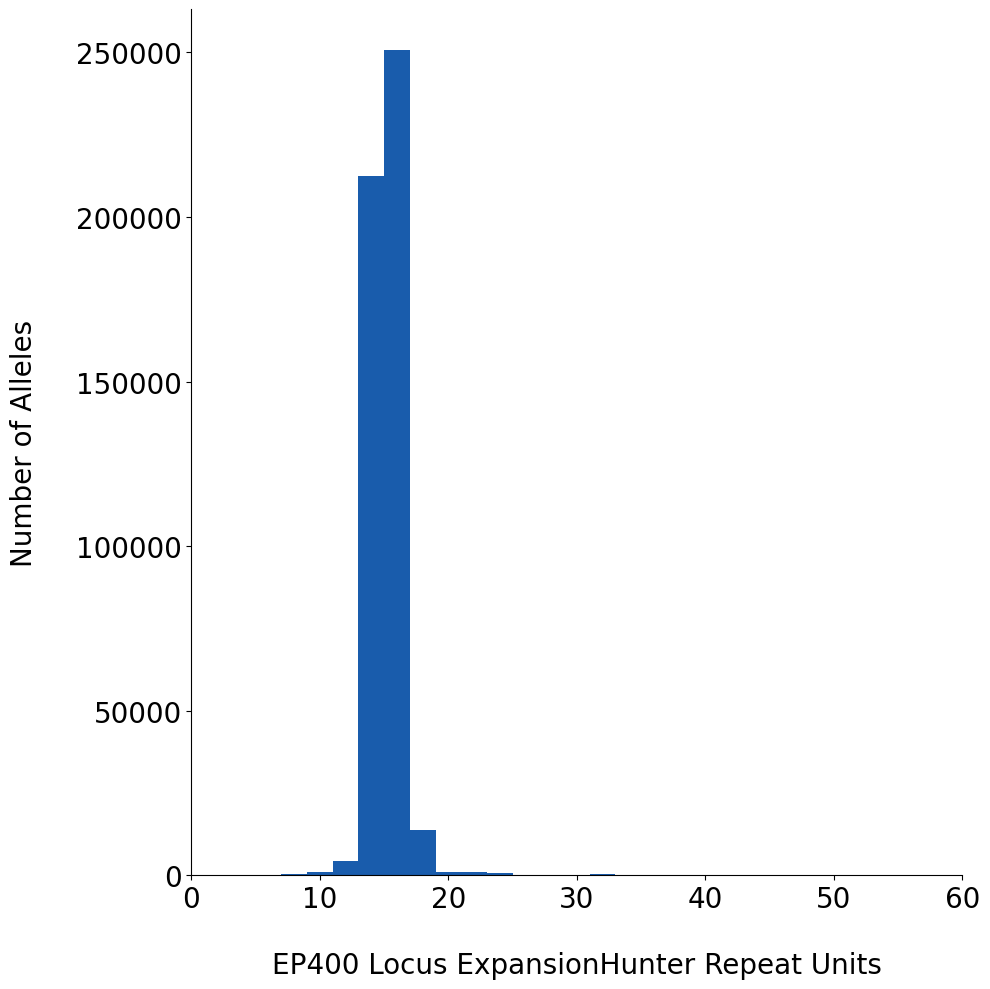

In [ ]:
# initial data loading and package import
import pandas
import matplotlib.pyplot as plt
import matplotlib as mpl
ehLengths=pandas.read_csv('assets/EP400_EH_AlleleLengths_245381_samples.txt',sep='\t',low_memory=False,header=None,names=['EHLength'])
# plot histogram of the distribution of CAG LPS values
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
fig, ax = plt.subplots(figsize=(10, 10))
plt.hist(ehLengths.loc[:,'EHLength'].values,color=colorPalette[5],bins=22)
plt.xlabel('\nEP400 Locus ExpansionHunter Repeat Units',fontsize=20)
plt.ylabel('Number of Alleles\n',fontsize=20)
plt.xticks(fontsize=20)
plt.xlim([0,60])
plt.yticks(fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure18B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure18B.svg')

# S19: EP400 Gene Expression Analysis

In [18]:
# I have no code for this figure

# S20: FAM193B Population Stats

## S20A

In [ ]:
import pandas
FAM193B_Alleles=pandas.read_csv('assets/FAM193B_alleleInfo_noIDs.txt',sep='\t',header=None,names=['TRID','allele1','allele2','allele1_lps_length','allele1_lps_motif','allele2_lps_length','allele2_lps_motif','allele1_len','allele2_len'])
outputBaseName="figures/SupplementaryFigure20A"
kmers=[3]
create_waterfall_plot(FAM193B_Alleles, outputBaseName, kmers, N_kmers=2)
# Note, we are using same 'create_waterfall_plot' function used in S18A above

Found 1086 total alleles.
Found 43 unique alleles.
Plotting all 43 alleles.
Extracting k-mers (sizes: [3])...
Found 9 unique k-mers.
Filtering subsequence k-mers...
After filtering: 9 k-mers remain.

Top 2 k-mers:
  CCG: 3173 occurrences
  ACG: 44 occurrences

Waterfall plot saved to: figures/SupplementaryFigure20A


In [26]:
FAM193B_Alleles.sort_values(by='allele2_len',ascending=False).loc[:,'allele2_lps_length'].iloc[:5]

249    372
97     123
428    114
497    114
98     111
Name: allele2_lps_length, dtype: int64

## S20B

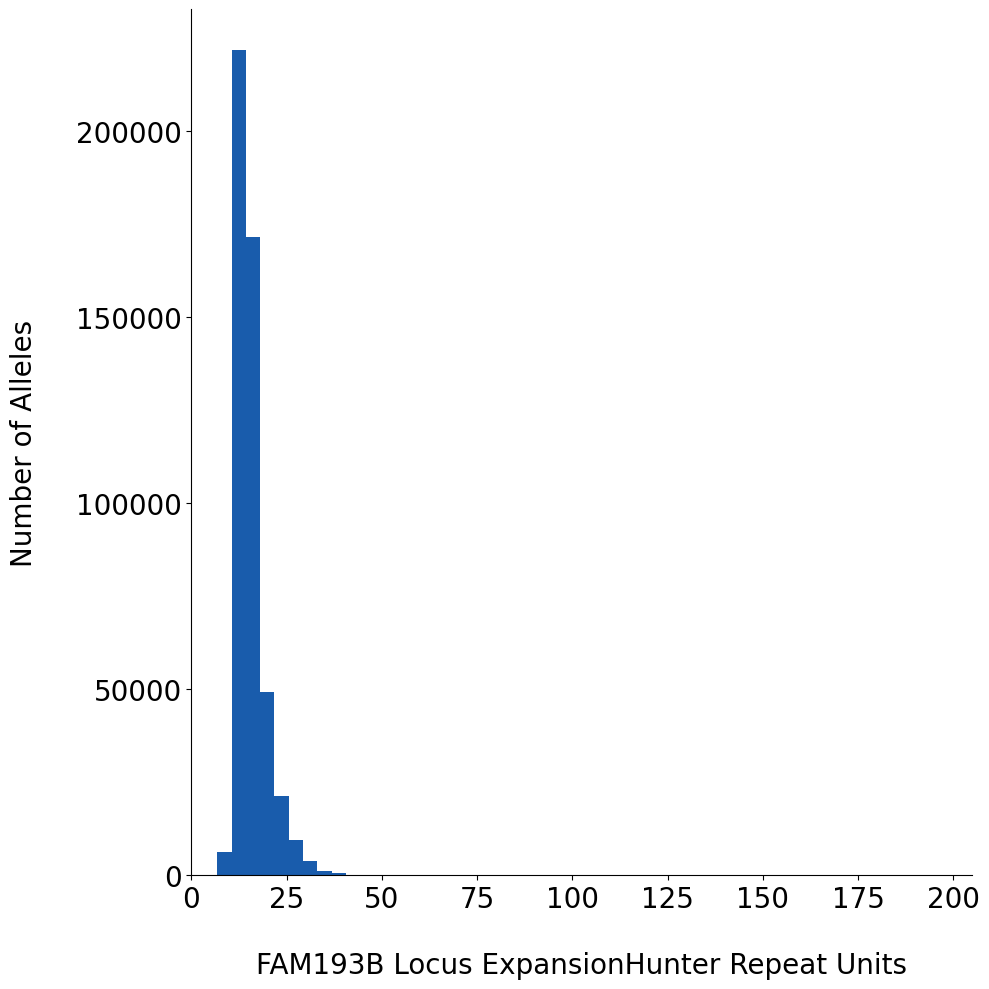

In [ ]:
# initial data loading and package import
import pandas
import matplotlib.pyplot as plt
import matplotlib as mpl
ehLengths=pandas.read_csv('assets/FAM193B_EH_AlleleLengths_245381_samples.txt',sep='\t',low_memory=False,header=None,names=['EHLength'])
# plot histogram of the distribution of CGG LPS values
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
fig, ax = plt.subplots(figsize=(10, 10))
plt.hist(ehLengths.loc[:,'EHLength'].values,color=colorPalette[5],bins=25)
plt.xlabel('\nFAM193B Locus ExpansionHunter Repeat Units',fontsize=20)
plt.ylabel('Number of Alleles\n',fontsize=20)
plt.xticks(fontsize=20)
plt.xlim([0,205])
plt.yticks(fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure20B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure20B.svg')

# S21: TR Constraint Overview

In [19]:
# I have no code for this figure

# S22: TR Length Constraint Technical Reliability Stats

## S22A

In [1]:
import pandas
constraintScores=pandas.read_csv('assets/constraintAnalyses/testing_within10kbOfGenes_scoredNT3.bed.gz',sep='\t')
constraintScores['OE_len']=(constraintScores.loc[:,'combinedLPSStdev']+0.1)/(constraintScores.loc[:,'expectedCombinedLPSStdev']+0.1)
constraintScores['OE_alleleLen']=(constraintScores.loc[:,'totalLengthStdev']+0.1)/(constraintScores.loc[:,'expectedTotalLengthStdev']+0.1)
constraintScores

,chr,start,end,TRID,mclpsmMedian,mclpsmMAD,mclpsmMean,mclpsmStdev,numUniqueMotifs,lpsMotifVariability,...,combinedLPSStdev,CPS,expectedMCLPSStdev,expectedLPSMotifVariability,expectedNumUniqueMotifs,expectedTotalLengthStdev,expectedCombinedLPSStdev,expectedCPS,OE_len,OE_alleleLen
0,chr1,49834,49853,1-49834-49853-AAAC,16.0,0.0,14.409266,1.958623,1.0,0.000000,...,1.958623,0.000000,0.251014,0.000185,0.998768,0.298351,0.265686,-0.000012,5.629478,5.167864
1,chr1,49846,49861,1-49846-49861-AAACA,15.0,0.0,13.011583,2.448279,1.0,0.000000,...,2.448279,0.000000,0.242102,-0.000023,1.019092,0.301024,0.286252,0.000159,6.597447,5.133410
2,chr1,50139,50148,1-50139-50148-TAA,9.0,0.0,9.000000,0.000000,1.0,0.000000,...,0.000000,0.000000,0.085031,-0.000189,1.004601,0.116549,0.090875,-0.000012,0.523902,0.461788
3,chr1,50481,50513,1-50481-50513-GT,34.0,2.0,28.345560,10.604178,1.0,0.000000,...,10.604178,0.000000,4.032983,0.000199,0.986159,3.891605,4.014409,-0.000307,2.601632,1.843264
4,chr1,50519,50529,1-50519-50529-GA,10.0,0.0,9.998069,0.062137,1.0,0.000000,...,0.062137,0.000000,0.526168,0.003249,1.472237,4.105489,0.633018,0.006775,0.221191,0.595628
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3404392,chr9,138242440,138242451,9-138242440-138242451-GT,10.0,0.0,10.000000,0.000000,1.0,0.000000,...,0.000000,0.000000,0.091715,-0.000047,1.007048,0.116549,0.086305,-0.000369,0.536754,0.461788
3404393,chr9,138242537,138242563,9-138242537-138242552-TCTT,12.0,0.0,12.000000,0.000000,3.0,0.090239,...,1.862577,0.228504,0.290004,0.000247,1.027419,0.529613,0.323957,0.000143,4.629193,9.792320
3404394,chr9,138242549,138242562,9-138242549-138242562-TC,12.0,0.0,11.354686,1.032114,2.0,0.111878,...,1.993616,0.173850,0.308941,-0.000085,1.010153,0.399946,0.306818,-0.000261,5.146317,12.311249
3404395,chr9,138242561,138242578,9-138242561-138242578-T,24.0,5.0,22.639963,5.986330,1.0,0.000000,...,5.986330,0.000000,0.978444,0.000133,0.986536,1.132499,0.984353,-0.000276,5.612867,13.834343


In [2]:
tmp=constraintScores.loc[((constraintScores['OE_len']<10) & (constraintScores['OE_len']>0)),:]
print(f'Percent of loci with OE_len values under 10, but above 0: {100*len(tmp)/len(constraintScores)}')
tmp=constraintScores.loc[((constraintScores['OE_alleleLen']<10) & (constraintScores['OE_alleleLen']>0)),:]
print(f'Percent of loci with OE_alleleLen values under 10, but above 0: {100*len(tmp)/len(constraintScores)}')

Percent of loci with OE_len values under 10, but above 0: 99.14257943477214
Percent of loci with OE_alleleLen values under 10, but above 0: 98.22080092304158


C:\Users\Matt\AppData\Local\Temp\ipykernel_277412\3987729740.py:4: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-white')


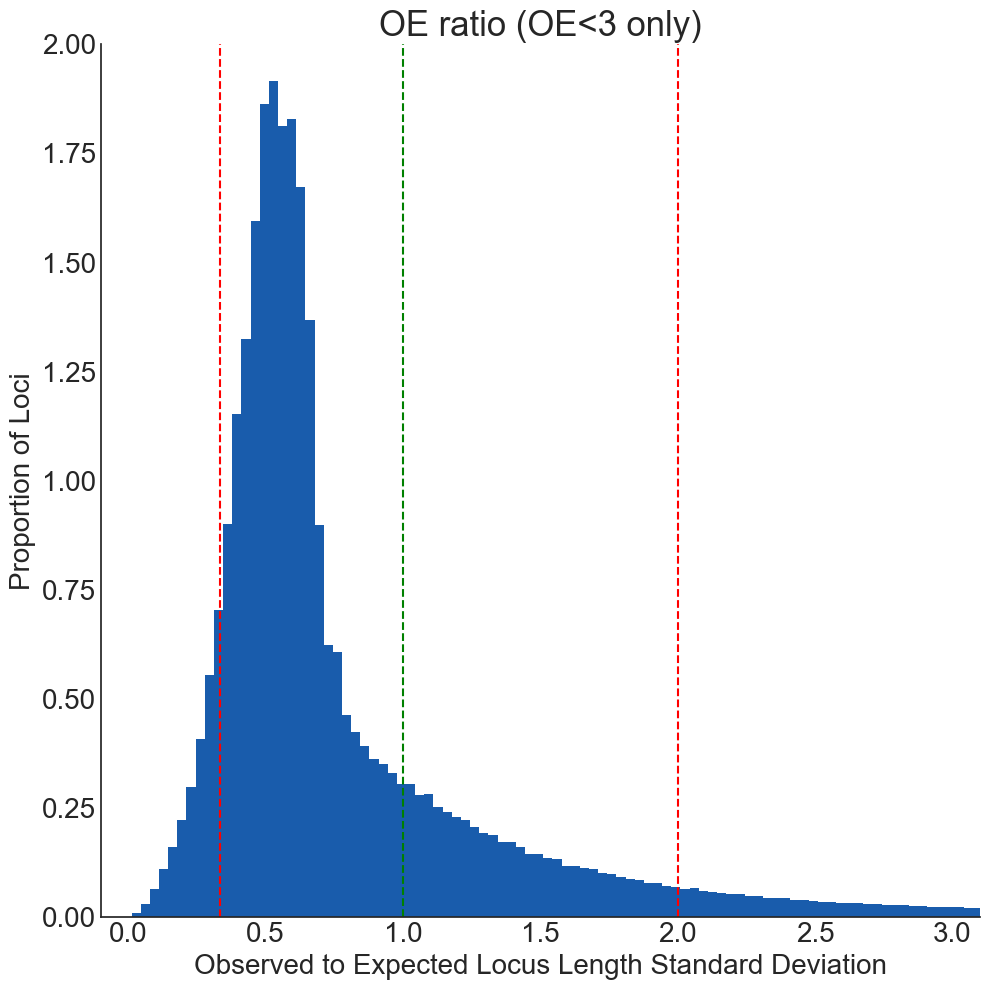

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
plt.style.use('seaborn-white')
fig, ax = plt.subplots(figsize=(10, 10))
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
plt.hist(constraintScores.loc[((constraintScores['OE_len']<10) & (constraintScores['OE_len']>0)),'OE_len'].values,bins=300,density=True,color=colorPalette[5])
plt.xlabel('Observed to Expected Locus Length Standard Deviation',fontsize=20)
plt.ylabel('Proportion of Loci',fontsize=20)
plt.title('OE ratio (OE<3 only)',fontsize=25)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.xlim([-0.1,3.1])
plt.plot([0.333,0.333],[0,3],'r--')
plt.plot([1,1],[0,3],'g--')
plt.plot([2,2],[0,3],'r--')
plt.ylim([0,2])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure22A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure22A.svg',dpi=600)

In [7]:
import scipy.stats
scipy.stats.spearmanr(constraintScores.loc[:,'combinedLPSStdev'].values,constraintScores.loc[:,'expectedCombinedLPSStdev'].values)
# very consistent with validation results

SignificanceResult(statistic=0.7360716748321064, pvalue=0.0)

## S22B

Pearson Correlation Coefficient: PearsonRResult(statistic=0.6026821829787234, pvalue=0.0134746866872207)


C:\Users\Matt\AppData\Local\Temp\ipykernel_277412\224105786.py:6: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-white')


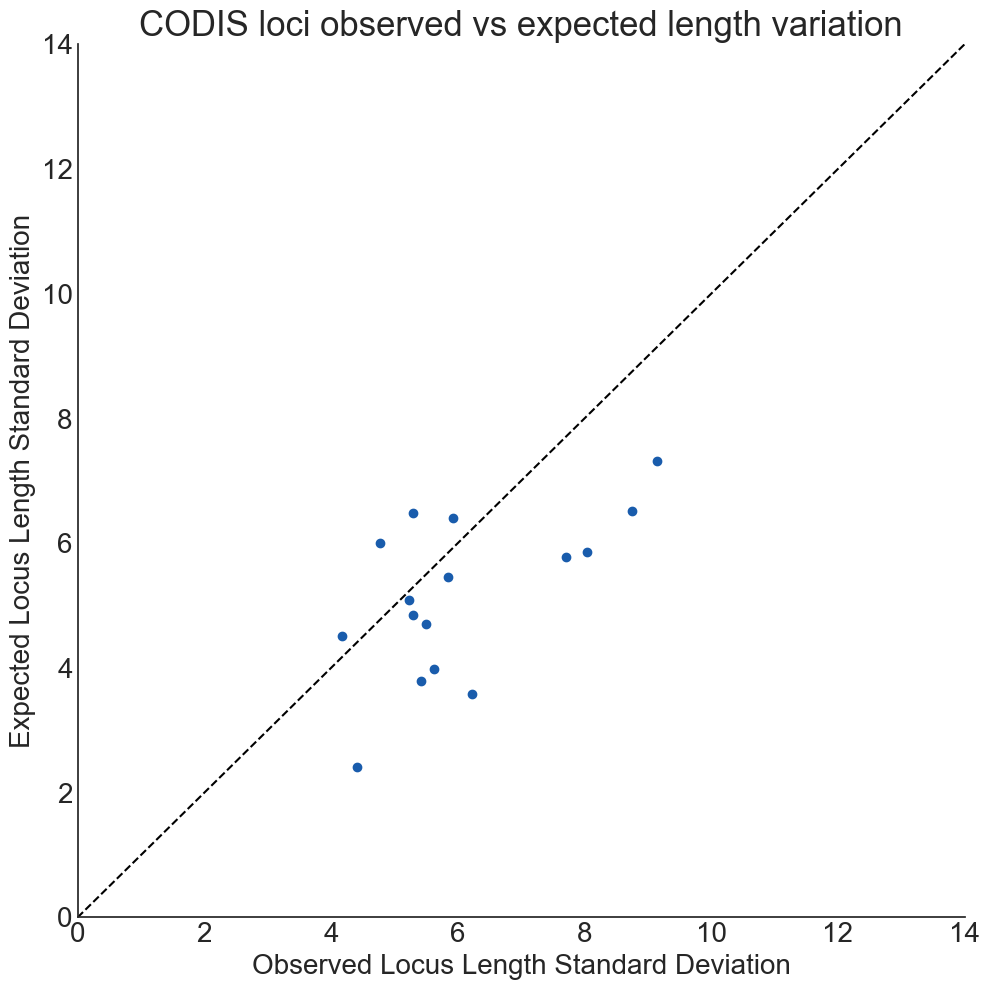

In [ ]:
codis=pandas.read_csv('assets/CODIS_TRExplorer_TRIDs.txt',sep='\t',low_memory=False,header=None,names=['TRID'])
codisPredictions=constraintScores.merge(codis,how='inner',on='TRID').loc[:,['TRID','combinedLPSStdev','expectedCombinedLPSStdev','OE_len',
                                                               'totalLengthStdev','expectedTotalLengthStdev','OE_alleleLen']]
print(f'Pearson Correlation Coefficient: {scipy.stats.pearsonr(codisPredictions.loc[:,"combinedLPSStdev"].values,codisPredictions.loc[:,"expectedCombinedLPSStdev"].values)}')
import matplotlib.pyplot as plt
plt.style.use('seaborn-white')
fig, ax = plt.subplots(figsize=(10, 10))
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
plt.scatter(codisPredictions.loc[:,'combinedLPSStdev'].values,codisPredictions.loc[:,'expectedCombinedLPSStdev'].values,color=colorPalette[5])
plt.xlabel('Observed Locus Length Standard Deviation',fontsize=20)
plt.ylabel('Expected Locus Length Standard Deviation',fontsize=20)
plt.title('CODIS loci observed vs expected length variation',fontsize=25)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.plot([0,15],[0,15],'k--')
plt.xlim([0,14])
plt.ylim([0,14])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure22B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure22B.svg',dpi=600)

## S22C

Pearson Correlation Coefficient: PearsonRResult(statistic=0.835567228852454, pvalue=0.0)
Spearman Correlation Coefficient: SignificanceResult(statistic=0.8317072363775473, pvalue=0.0)


C:\Users\Matt\AppData\Local\Temp\ipykernel_277412\1215705493.py:17: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use('seaborn-white')


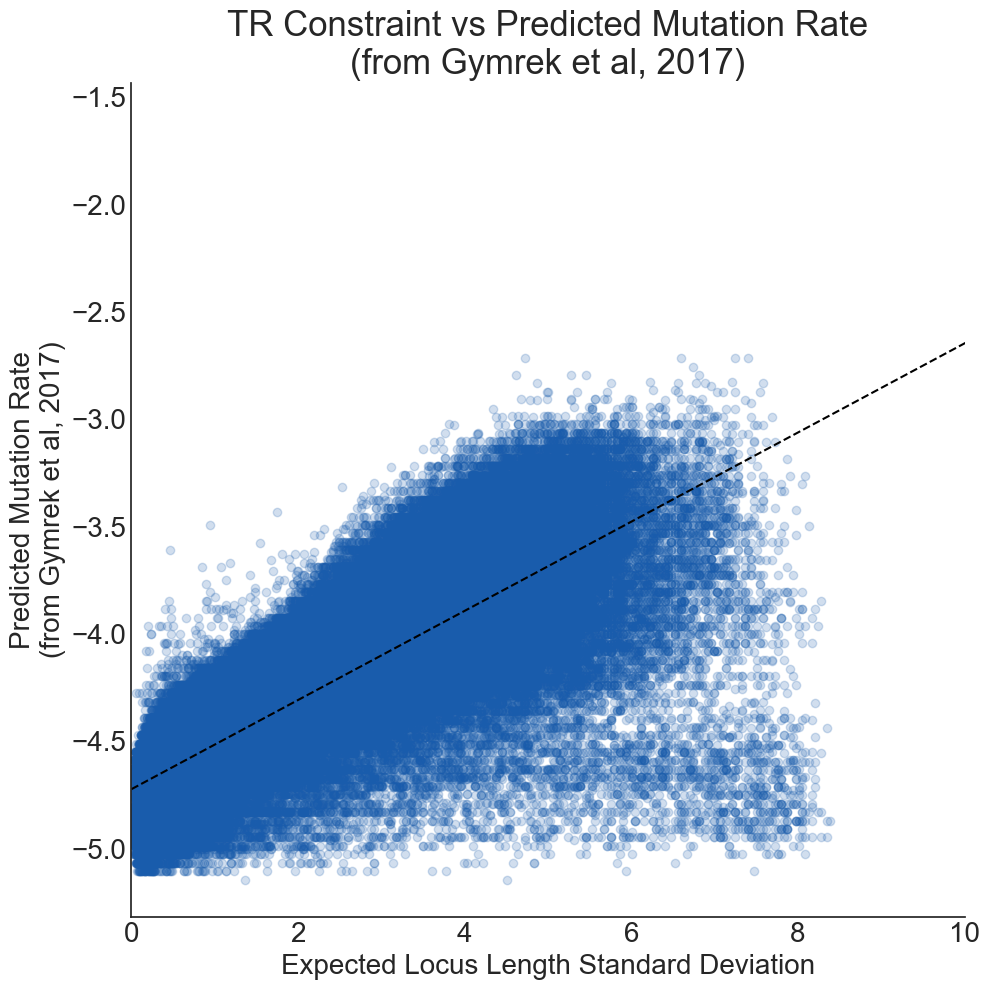

In [ ]:
# TR Length Constraint vs Gymrek Constraint and its measures
import pandas
import scipy.stats
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from numpy.polynomial.polynomial import polyfit
constraintScores=pandas.read_csv('assets/constraintAnalyses/testing_within10kbOfGenes_scoredNT3.bed.gz',sep='\t')
constraintScores['OE_len']=(constraintScores.loc[:,'combinedLPSStdev']+0.1)/(constraintScores.loc[:,'expectedCombinedLPSStdev']+0.1)
gymrekConstraint=pandas.read_csv('assets/GymrekConstraint_hg38_with_TRExplorer_TRIDs.txt',sep='\t')
combined=constraintScores.merge(gymrekConstraint,how='inner',on='TRID')
tmp=combined.loc[:,['expectedCombinedLPSStdev','pred_mu_1']].dropna()


print(f'Pearson Correlation Coefficient: {scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"pred_mu_1"].values)}')
print(f'Spearman Correlation Coefficient: {scipy.stats.spearmanr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"pred_mu_1"].values)}')
plt.style.use('seaborn-white')
fig, ax = plt.subplots(figsize=(10, 10))
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
ax.scatter(tmp.loc[:,'expectedCombinedLPSStdev'].values, tmp.loc[:,'pred_mu_1'].values,color=colorPalette[5],alpha=0.2)

# add best fit line
b,m=polyfit(tmp.loc[:,'expectedCombinedLPSStdev'].values,tmp.loc[:,'pred_mu_1'].values,1)
x=np.arange(0,16)
plt.plot(x,b+m*x, '--k')

plt.xlabel('Expected Locus Length Standard Deviation',fontsize=20)
plt.ylabel('Predicted Mutation Rate\n(from Gymrek et al, 2017)',fontsize=20)
plt.title('TR Constraint vs Predicted Mutation Rate\n(from Gymrek et al, 2017)',fontsize=25)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xlim([0,10])
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure22C.png',dpi=600)
plt.savefig('figures/SupplementaryFigure22C.svg')

In [10]:
tmp=combined.loc[:,['expectedCombinedLPSStdev','est_logmu_ml']].dropna()
print(f'Pearson Correlation Coefficient: {scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"est_logmu_ml"].values)}')
print(f'Spearman Correlation Coefficient: {scipy.stats.spearmanr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"est_logmu_ml"].values)}')

Pearson Correlation Coefficient: PearsonRResult(statistic=0.47660082942801146, pvalue=0.0)
Spearman Correlation Coefficient: SignificanceResult(statistic=0.6408417503780804, pvalue=0.0)


In [6]:
tmp=combined.loc[:,['expectedCombinedLPSStdev','pred_mu_1']].dropna()
print(f'Pearson Correlation Coefficient: {scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"pred_mu_1"].values)}')
print(f'Spearman Correlation Coefficient: {scipy.stats.spearmanr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"pred_mu_1"].values)}')

Pearson Correlation Coefficient: PearsonRResult(statistic=0.835567228852454, pvalue=0.0)
Spearman Correlation Coefficient: SignificanceResult(statistic=0.8317072363775473, pvalue=0.0)


In [12]:
tmp=combined.loc[:,['combinedLPSStdev','est_logmu_ml']].dropna()
print(f'Pearson Correlation Coefficient: {scipy.stats.pearsonr(tmp.loc[:,"combinedLPSStdev"].values,tmp.loc[:,"est_logmu_ml"].values)}')
print(f'Spearman Correlation Coefficient: {scipy.stats.spearmanr(tmp.loc[:,"combinedLPSStdev"].values,tmp.loc[:,"est_logmu_ml"].values)}')

Pearson Correlation Coefficient: PearsonRResult(statistic=0.17756113047610803, pvalue=0.0)
Spearman Correlation Coefficient: SignificanceResult(statistic=0.7087406886013763, pvalue=0.0)


## S22D

In [15]:
# split up validation set performance by STR motif length 
import pandas
constraintScores=pandas.read_csv('assets/constraintAnalyses/validation_10kbFromGenes_scoredNT3.bed.gz',sep='\t')
constraintScores['OE_len']=(constraintScores.loc[:,'combinedLPSStdev']+0.1)/(constraintScores.loc[:,'expectedCombinedLPSStdev']+0.1)
# get most common LPS Motif length for each TR
lps=pandas.read_csv('statsTables/statsTables_v8_over25x_lpsPerMotifStats_trgt.TR_Explorer_1.0.1.txt.gz',sep='\t')
lps=lps.sort_values(by='N_motif',ascending=False).drop_duplicates(subset='TRID',keep='first').sort_values(by='TRID',ascending=True)
lps['motifLen']=lps.loc[:,'LPS_Motif'].str.len()
constraintScores2=constraintScores.merge(lps.loc[:,['TRID','motifLen']],how='inner',on='TRID')
constraintScores2

,chr,start,end,TRID,mclpsmMedian,mclpsmMAD,mclpsmMean,mclpsmStdev,numUniqueMotifs,lpsMotifVariability,...,combinedLPSStdev,CPS,expectedMCLPSStdev,expectedLPSMotifVariability,expectedNumUniqueMotifs,expectedTotalLengthStdev,expectedCombinedLPSStdev,expectedCPS,OE_len,motifLen
0,chr1,2896771,2896800,1-2896771-2896800-ACACATGC,24.0,0.0,23.992599,0.243320,1.0,0.0,...,0.243320,0.0,2.589262,0.000128,1.087590,3.870216,2.707326,0.000609,0.122294,8
1,chr1,2898896,2898906,1-2898896-2898906-GTG,9.0,0.0,8.983425,0.315062,1.0,0.0,...,0.315062,0.0,0.100627,-0.000108,1.004790,0.162000,0.141148,-0.000152,1.721194,3
2,chr1,2899043,2899075,1-2899043-2899075-AAAC,28.0,0.0,27.937385,1.230841,1.0,0.0,...,1.230841,0.0,3.159621,0.000325,1.003660,3.164399,3.210050,0.000718,0.402061,4
3,chr1,2911963,2911974,1-2911963-2911974-TG,10.0,0.0,9.996317,0.085789,1.0,0.0,...,0.085789,0.0,0.109539,0.000180,1.004225,0.194082,0.104586,0.000104,0.908120,2
4,chr1,2937986,2937996,1-2937986-2937996-CA,10.0,0.0,9.998158,0.060690,1.0,0.0,...,0.060690,0.0,0.140730,-0.000288,0.997639,0.351822,0.127437,-0.000447,0.706524,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56685,chr9,135386682,135386699,9-135386682-135386699-A,17.0,0.0,17.124309,0.641296,1.0,0.0,...,0.641296,0.0,1.025232,0.000114,0.995757,1.137846,1.014060,-0.000416,0.665401,1
56686,chr9,135388341,135388350,9-135388341-135388350-GTG,9.0,0.0,8.997238,0.091035,1.0,0.0,...,0.091035,0.0,0.107311,-0.000123,1.001402,0.089814,0.116012,-0.000338,0.884372,3
56687,chr9,136184164,136184184,9-136184164-136184184-TGTTTT,18.0,0.0,17.994475,0.182069,1.0,0.0,...,0.182069,0.0,0.238760,0.000270,1.011564,0.226165,0.265686,0.000496,0.771342,6
56688,chr9,136185166,136185177,9-136185166-136185177-GCT,9.0,0.0,9.000000,0.000000,1.0,0.0,...,0.000000,0.0,0.080575,-0.000246,1.003096,0.079120,0.084020,-0.000113,0.543419,3


In [20]:
import scipy.stats
# 1bp
tmp=constraintScores2.loc[constraintScores2['motifLen']==1,:]
print(f'1bp Pearson Correlation Coefficient: {scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'1bp Spearman Correlation Coefficient: {scipy.stats.spearmanr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'N: {len(tmp)}')
# 2bp
tmp=constraintScores2.loc[constraintScores2['motifLen']==2,:]
print(f'2bp Pearson Correlation Coefficient: {scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'2bp Spearman Correlation Coefficient: {scipy.stats.spearmanr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'N: {len(tmp)}')
# 3bp
tmp=constraintScores2.loc[constraintScores2['motifLen']==3,:]
print(f'3bp Pearson Correlation Coefficient: {scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'3bp Spearman Correlation Coefficient: {scipy.stats.spearmanr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'N: {len(tmp)}')
# 4bp
tmp=constraintScores2.loc[constraintScores2['motifLen']==4,:]
print(f'4bp Pearson Correlation Coefficient: {scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'4bp Spearman Correlation Coefficient: {scipy.stats.spearmanr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'N: {len(tmp)}')
# 5bp
tmp=constraintScores2.loc[constraintScores2['motifLen']==5,:]
print(f'5bp Pearson Correlation Coefficient: {scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'5bp Spearman Correlation Coefficient: {scipy.stats.spearmanr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'N: {len(tmp)}')
# 6bp
tmp=constraintScores2.loc[constraintScores2['motifLen']==6,:]
print(f'6bp Pearson Correlation Coefficient: {scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'6bp Spearman Correlation Coefficient: {scipy.stats.spearmanr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'N: {len(tmp)}')
# 7+bp
tmp=constraintScores2.loc[constraintScores2['motifLen']>6,:]
print(f'7+bp Pearson Correlation Coefficient: {scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'7+bp Spearman Correlation Coefficient: {scipy.stats.spearmanr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)}')
print(f'N: {len(tmp)}')

1bp Pearson Correlation Coefficient: PearsonRResult(statistic=0.6139374896861908, pvalue=0.0)
1bp Spearman Correlation Coefficient: SignificanceResult(statistic=0.7592225568852601, pvalue=0.0)
N: 15888
2bp Pearson Correlation Coefficient: PearsonRResult(statistic=0.7668488708788461, pvalue=0.0)
2bp Spearman Correlation Coefficient: SignificanceResult(statistic=0.7120437220883343, pvalue=0.0)
N: 12248
3bp Pearson Correlation Coefficient: PearsonRResult(statistic=0.5894041389625309, pvalue=0.0)
3bp Spearman Correlation Coefficient: SignificanceResult(statistic=0.24791212817271366, pvalue=1.277505769072444e-259)
N: 18680
4bp Pearson Correlation Coefficient: PearsonRResult(statistic=0.8153081209875135, pvalue=0.0)
4bp Spearman Correlation Coefficient: SignificanceResult(statistic=0.6234515546200152, pvalue=0.0)
N: 6839
5bp Pearson Correlation Coefficient: PearsonRResult(statistic=0.6567354478156293, pvalue=3.895501794196255e-242)
5bp Spearman Correlation Coefficient: SignificanceResult(sta

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


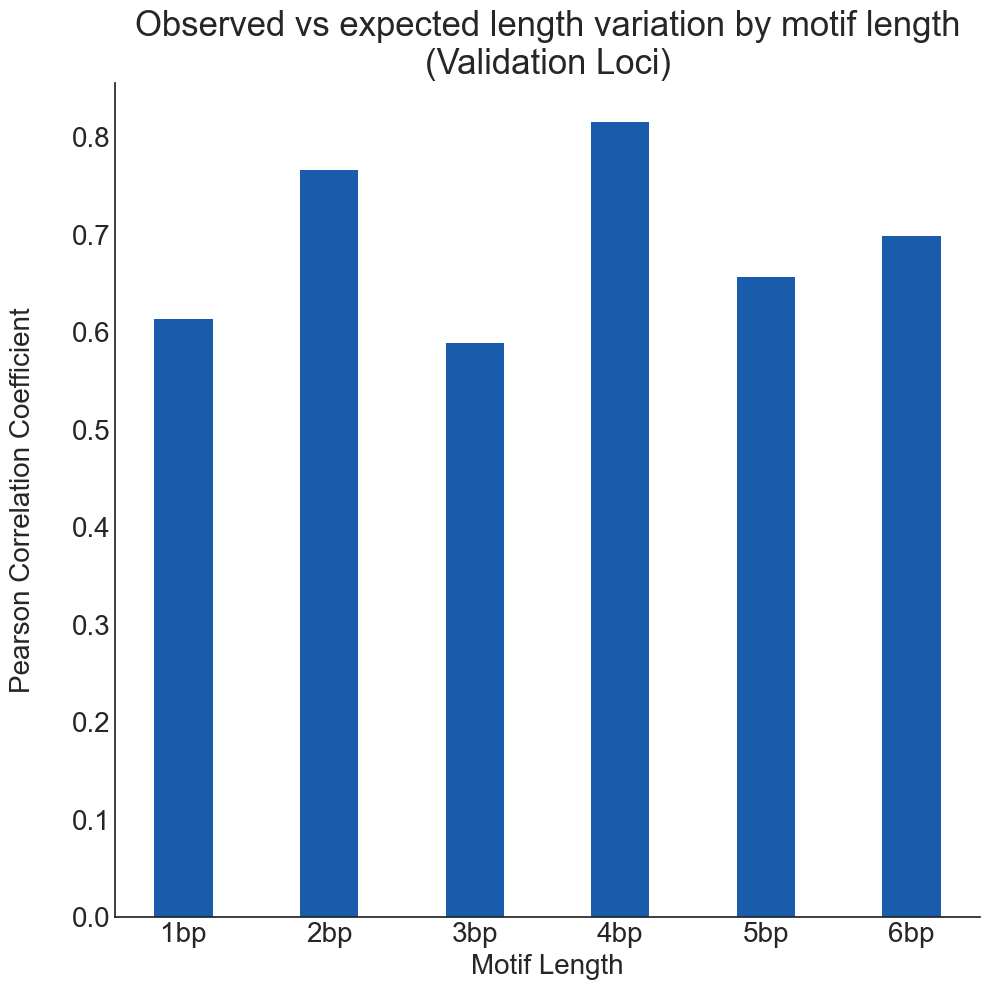

In [ ]:
# Scatterplot with different colors for different motif lengths
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
import matplotlib
from matplotlib import pyplot as plt
import numpy as np
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(10, 10))

PCC_vals=[]
# 1bp
tmp=constraintScores2.loc[constraintScores2['motifLen']==1,:]
pcc, p_val = scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)
PCC_vals.append(pcc)
# 2bp
tmp=constraintScores2.loc[constraintScores2['motifLen']==2,:]
pcc, p_val = scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)
PCC_vals.append(pcc)
# 3bp
tmp=constraintScores2.loc[constraintScores2['motifLen']==3,:]
pcc, p_val = scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)
PCC_vals.append(pcc)
# 4bp
tmp=constraintScores2.loc[constraintScores2['motifLen']==4,:]
pcc, p_val = scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)
PCC_vals.append(pcc)
# 5bp
tmp=constraintScores2.loc[constraintScores2['motifLen']==5,:]
pcc, p_val = scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)
PCC_vals.append(pcc)
# 6bp
tmp=constraintScores2.loc[constraintScores2['motifLen']==6,:]
pcc, p_val = scipy.stats.pearsonr(tmp.loc[:,"expectedCombinedLPSStdev"].values,tmp.loc[:,"combinedLPSStdev"].values)
PCC_vals.append(pcc)


width=0.4
xlabels=["1bp","2bp","3bp","4bp","5bp","6bp"]
plt.bar(xlabels,PCC_vals,width,color=colorPalette[5])


plt.xticks(xlabels,fontsize=20)
plt.ylabel('Pearson Correlation Coefficient\n',fontsize=20)
plt.xlabel('Motif Length',fontsize=20)
plt.title('Observed vs expected length variation by motif length\n(Validation Loci)',fontsize=25)
plt.yticks(fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.legend(fontsize=20)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure22D.png',dpi=600)
plt.savefig('figures/SupplementaryFigure22D.svg')

# S23: TR Length Constraint Biological Performance

## S23A

In [1]:
import pandas
constraintScores=pandas.read_csv('assets/constraintAnalyses/testing_within10kbOfGenes_scoredNT3.bed.gz',sep='\t')
constraintScores['OE_len']=(constraintScores.loc[:,'combinedLPSStdev']+0.1)/(constraintScores.loc[:,'expectedCombinedLPSStdev']+0.1)
constraintScores['OE_alleleLen']=(constraintScores.loc[:,'totalLengthStdev']+0.1)/(constraintScores.loc[:,'expectedTotalLengthStdev']+0.1)

pathogenic=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t',low_memory=False)
sulovariAbInitio=pandas.read_csv('assets/Sulovari_abInitio_TRExplorer_TRIDs.txt',sep='\t',low_memory=False,header=None,names=['TRID'])
sulovariHSE=pandas.read_csv('assets/Sulovari_HSE_TRExplorer_TRIDs.txt',sep='\t',low_memory=False,header=None,names=['TRID'])
codis=pandas.read_csv('assets/CODIS_TRExplorer_TRIDs.txt',sep='\t',low_memory=False,header=None,names=['TRID'])
eSTR=pandas.read_csv('assets/eSTR_TRExplorer_TRIDs_CAVIAR_0.3.txt',sep='\t',low_memory=False,header=None,names=['TRID'])
genicAnnotations=pandas.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',low_memory=False,header=None,names=['TRID','Region'])
coding=genicAnnotations.loc[genicAnnotations['Region']=='coding',:]

polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values
pathogenic = pathogenic.loc[pathogenic['TRID'].isin(otherPathogenicTRIDs),:].reset_index(drop=True)

# genic constraint deciles
constraintScores['OEDecile']=0
for idx in range(1,10):
    thresh=constraintScores.loc[:,'OE_len'].quantile(float(f'0.{idx}'))
    constraintScores.loc[constraintScores['OE_len']>thresh,'OEDecile']=idx

# observation deciles
constraintScores['ObsDecile']=0
for idx in range(1,10):
    thresh=constraintScores.loc[:,'combinedLPSStdev'].quantile(float(f'0.{idx}'))
    constraintScores.loc[constraintScores['combinedLPSStdev']>thresh,'ObsDecile']=idx

In [9]:
import scipy.stats
# pathogenic TRs with extra variance
a=len(constraintScores.loc[((constraintScores['OE_len']>2) & (constraintScores['TRID'].isin(pathogenic['TRID'].values))),:])
b=len(pathogenic.TRID.values)-a
c=len(constraintScores.loc[constraintScores['OE_len']>2,:])-a
d=len(constraintScores)-(a+b+c)
print(scipy.stats.fisher_exact([[a,b],[c,d]]))
res=scipy.stats.contingency.odds_ratio([[a,b],[c,d]])
print(res.confidence_interval(confidence_level=0.95))

SignificanceResult(statistic=9.62260907008818, pvalue=2.1065685130164322e-11)
ConfidenceInterval(low=5.000184716926306, high=18.518184987586146)


In [10]:
import scipy.stats
# pathogenic TRs with extra variance
a=len(constraintScores.loc[((constraintScores['OE_len']>2) & (constraintScores['TRID'].isin(sulovariAbInitio['TRID'].values))),:])
b=len(sulovariAbInitio.TRID.values)-a
c=len(constraintScores.loc[constraintScores['OE_len']>2,:])-a
d=len(constraintScores)-(a+b+c)
print(scipy.stats.fisher_exact([[a,b],[c,d]]))
res=scipy.stats.contingency.odds_ratio([[a,b],[c,d]])
print(res.confidence_interval(confidence_level=0.95))

SignificanceResult(statistic=6.228540821196295, pvalue=3.0834562355118797e-56)
ConfidenceInterval(low=5.05214590110929, high=7.660418599607387)


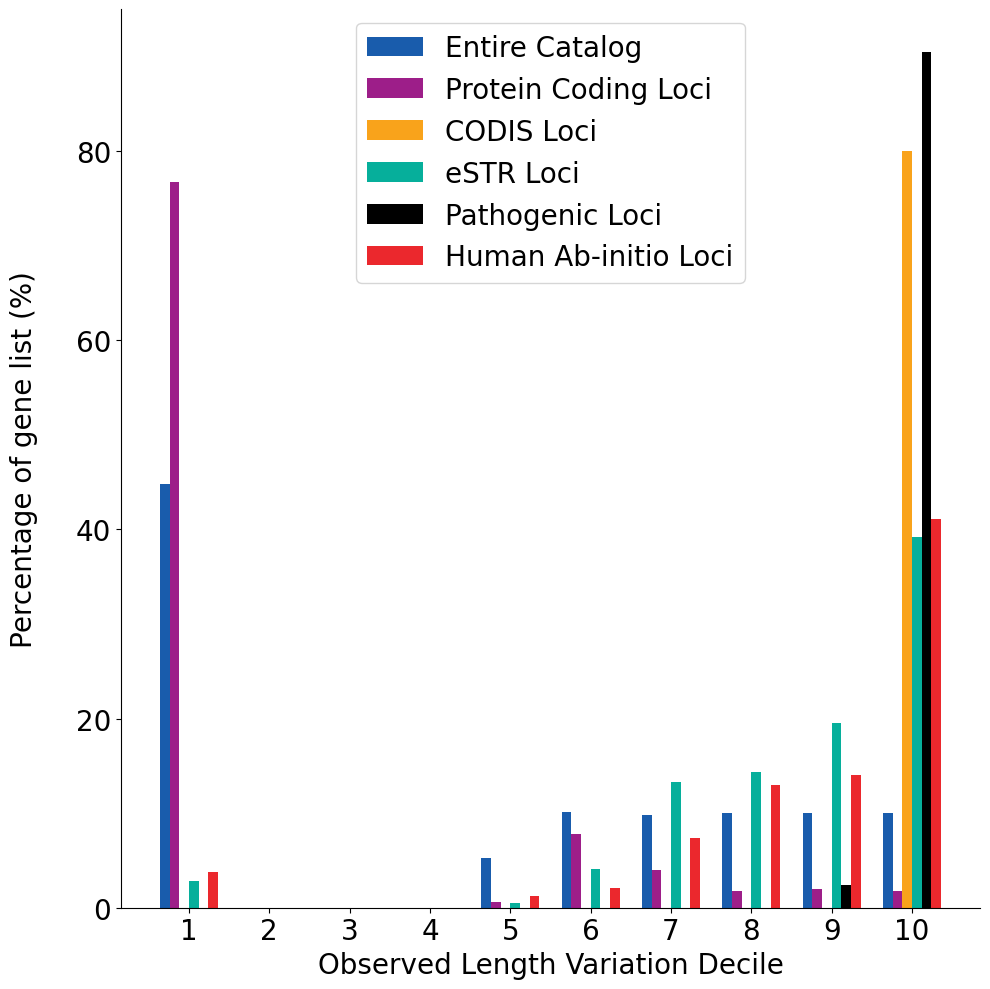

In [ ]:

colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
import matplotlib
from matplotlib import pyplot as plt
import numpy as np
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(10, 10))

catalogDeciles=100*constraintScores.loc[:,'ObsDecile'].value_counts().sort_index()/len(constraintScores)
proteinCodingDeciles=100*constraintScores.loc[constraintScores['TRID'].isin(coding['TRID'].values),'ObsDecile'].value_counts().sort_index()/len(coding)
codisDeciles=100*constraintScores.loc[constraintScores['TRID'].isin(codis['TRID'].values),'ObsDecile'].value_counts().sort_index()/len(codis)
abInitioDeciles=100*constraintScores.loc[constraintScores['TRID'].isin(sulovariAbInitio['TRID'].values),'ObsDecile'].value_counts().sort_index()/len(sulovariAbInitio)
eSTRDeciles=100*constraintScores.loc[constraintScores['TRID'].isin(eSTR['TRID'].values),'ObsDecile'].value_counts().sort_index()/len(eSTR)
pathoDeciles=100*constraintScores.loc[constraintScores['TRID'].isin(pathogenic['TRID'].values),'ObsDecile'].value_counts().sort_index()/len(pathogenic)

# add missing deciles to list
for i in range(10):
    if i not in catalogDeciles.index.values:
        catalogDeciles.loc[i]=0
    if i not in proteinCodingDeciles.index.values:
        proteinCodingDeciles.loc[i]=0
    if i not in codisDeciles.index.values:
        codisDeciles.loc[i]=0
    if i not in abInitioDeciles.index.values:
        abInitioDeciles.loc[i]=0
    if i not in eSTRDeciles.index.values:
        eSTRDeciles.loc[i]=0
    if i not in pathoDeciles.index.values:
        pathoDeciles.loc[i]=0
catalogDeciles=catalogDeciles.sort_index()
proteinCodingDeciles=proteinCodingDeciles.sort_index()
codisDeciles=codisDeciles.sort_index()
abInitioDeciles=abInitioDeciles.sort_index()
eSTRDeciles=eSTRDeciles.sort_index()
pathoDeciles=pathoDeciles.sort_index()


width=0.12
x=np.arange(1,11)

plt.bar(x-0.3,catalogDeciles.values,width,label='Entire Catalog',color=colorPalette[5])
plt.bar(x-0.3+width,proteinCodingDeciles.values,width,label='Protein Coding Loci',color=colorPalette[4])
plt.bar(x-0.3+width+width,codisDeciles.values,width,label='CODIS Loci',color=colorPalette[1])
plt.bar(x-0.3+width+width+width,eSTRDeciles.values,width,label='eSTR Loci',color=colorPalette[6])
plt.bar(x-0.3+width+width+width+width,pathoDeciles.values,width,label='Pathogenic Loci',color='k')
plt.bar(x-0.3+width+width+width+width+width,abInitioDeciles.values,width,label='Human Ab-initio Loci',color=colorPalette[2])

plt.xticks(x,fontsize=20)
plt.ylabel('Percentage of gene list (%)\n',fontsize=20)
plt.xlabel('Observed Length Variation Decile',fontsize=20)
plt.yticks(fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.legend(fontsize=20)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure23A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure23A.svg')

## S23B

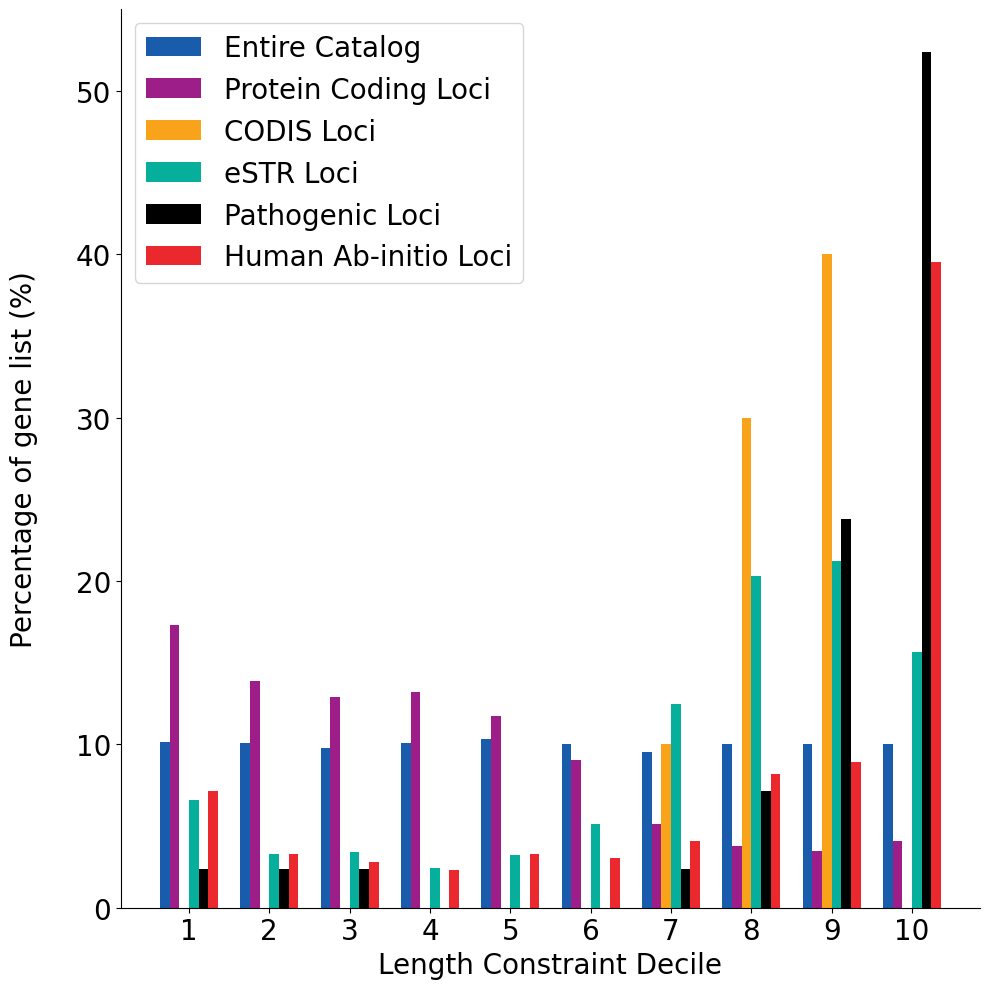

In [ ]:

colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
import matplotlib
from matplotlib import pyplot as plt
import numpy as np
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(10, 10))

catalogDeciles=100*constraintScores.loc[:,'OEDecile'].value_counts().sort_index()/len(constraintScores)
proteinCodingDeciles=100*constraintScores.loc[constraintScores['TRID'].isin(coding['TRID'].values),'OEDecile'].value_counts().sort_index()/len(coding)
codisDeciles=100*constraintScores.loc[constraintScores['TRID'].isin(codis['TRID'].values),'OEDecile'].value_counts().sort_index()/len(codis)
abInitioDeciles=100*constraintScores.loc[constraintScores['TRID'].isin(sulovariAbInitio['TRID'].values),'OEDecile'].value_counts().sort_index()/len(sulovariAbInitio)
eSTRDeciles=100*constraintScores.loc[constraintScores['TRID'].isin(eSTR['TRID'].values),'OEDecile'].value_counts().sort_index()/len(eSTR)
pathoDeciles=100*constraintScores.loc[constraintScores['TRID'].isin(pathogenic['TRID'].values),'OEDecile'].value_counts().sort_index()/len(pathogenic)

# add missing deciles to list
for i in range(10):
    if i not in catalogDeciles.index.values:
        catalogDeciles.loc[i]=0
    if i not in proteinCodingDeciles.index.values:
        proteinCodingDeciles.loc[i]=0
    if i not in codisDeciles.index.values:
        codisDeciles.loc[i]=0
    if i not in abInitioDeciles.index.values:
        abInitioDeciles.loc[i]=0
    if i not in eSTRDeciles.index.values:
        eSTRDeciles.loc[i]=0
    if i not in pathoDeciles.index.values:
        pathoDeciles.loc[i]=0
catalogDeciles=catalogDeciles.sort_index()
proteinCodingDeciles=proteinCodingDeciles.sort_index()
codisDeciles=codisDeciles.sort_index()
abInitioDeciles=abInitioDeciles.sort_index()
eSTRDeciles=eSTRDeciles.sort_index()
pathoDeciles=pathoDeciles.sort_index()


width=0.12
x=np.arange(1,11)

plt.bar(x-0.3,catalogDeciles.values,width,label='Entire Catalog',color=colorPalette[5])
plt.bar(x-0.3+width,proteinCodingDeciles.values,width,label='Protein Coding Loci',color=colorPalette[4])
plt.bar(x-0.3+width+width,codisDeciles.values,width,label='CODIS Loci',color=colorPalette[1])
plt.bar(x-0.3+width+width+width,eSTRDeciles.values,width,label='eSTR Loci',color=colorPalette[6])
plt.bar(x-0.3+width+width+width+width,pathoDeciles.values,width,label='Pathogenic Loci',color='k')
plt.bar(x-0.3+width+width+width+width+width,abInitioDeciles.values,width,label='Human Ab-initio Loci',color=colorPalette[2])

plt.xticks(x,fontsize=20)
plt.ylabel('Percentage of gene list (%)\n',fontsize=20)
plt.xlabel('Length Constraint Decile',fontsize=20)
plt.yticks(fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.legend(fontsize=20)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure23B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure23B.svg')

## S23C

In [1]:
# initial data loading and package import
import pandas
import matplotlib
from matplotlib import pyplot as plt
import numpy as np
from numpy.polynomial.polynomial import polyfit
constraintScores=pandas.read_csv('assets/constraintAnalyses/testing_within10kbOfGenes_scoredNT3.bed.gz',sep='\t')
constraintScores['OE_len']=(constraintScores.loc[:,'combinedLPSStdev']+0.1)/(constraintScores.loc[:,'expectedCombinedLPSStdev']+0.1)
constraintScores['OE_alleleLen']=(constraintScores.loc[:,'totalLengthStdev']+0.1)/(constraintScores.loc[:,'expectedTotalLengthStdev']+0.1)
ageOfOnset=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno_withAgeOfOnset.txt',sep='\t',low_memory=False)
constraintScores2=constraintScores.merge(ageOfOnset,how='inner',on='TRID')

# calculate pearson correlation (I added the correlation coefficient value to the figure manually in Illustrator using the value generated here)
from scipy.stats import pearsonr
print(pearsonr(np.log(constraintScores2.loc[:,'OE_len'].values),constraintScores2.loc[:,'mean_age'].values))

PearsonRResult(statistic=0.4051807781634372, pvalue=0.005216571689275076)


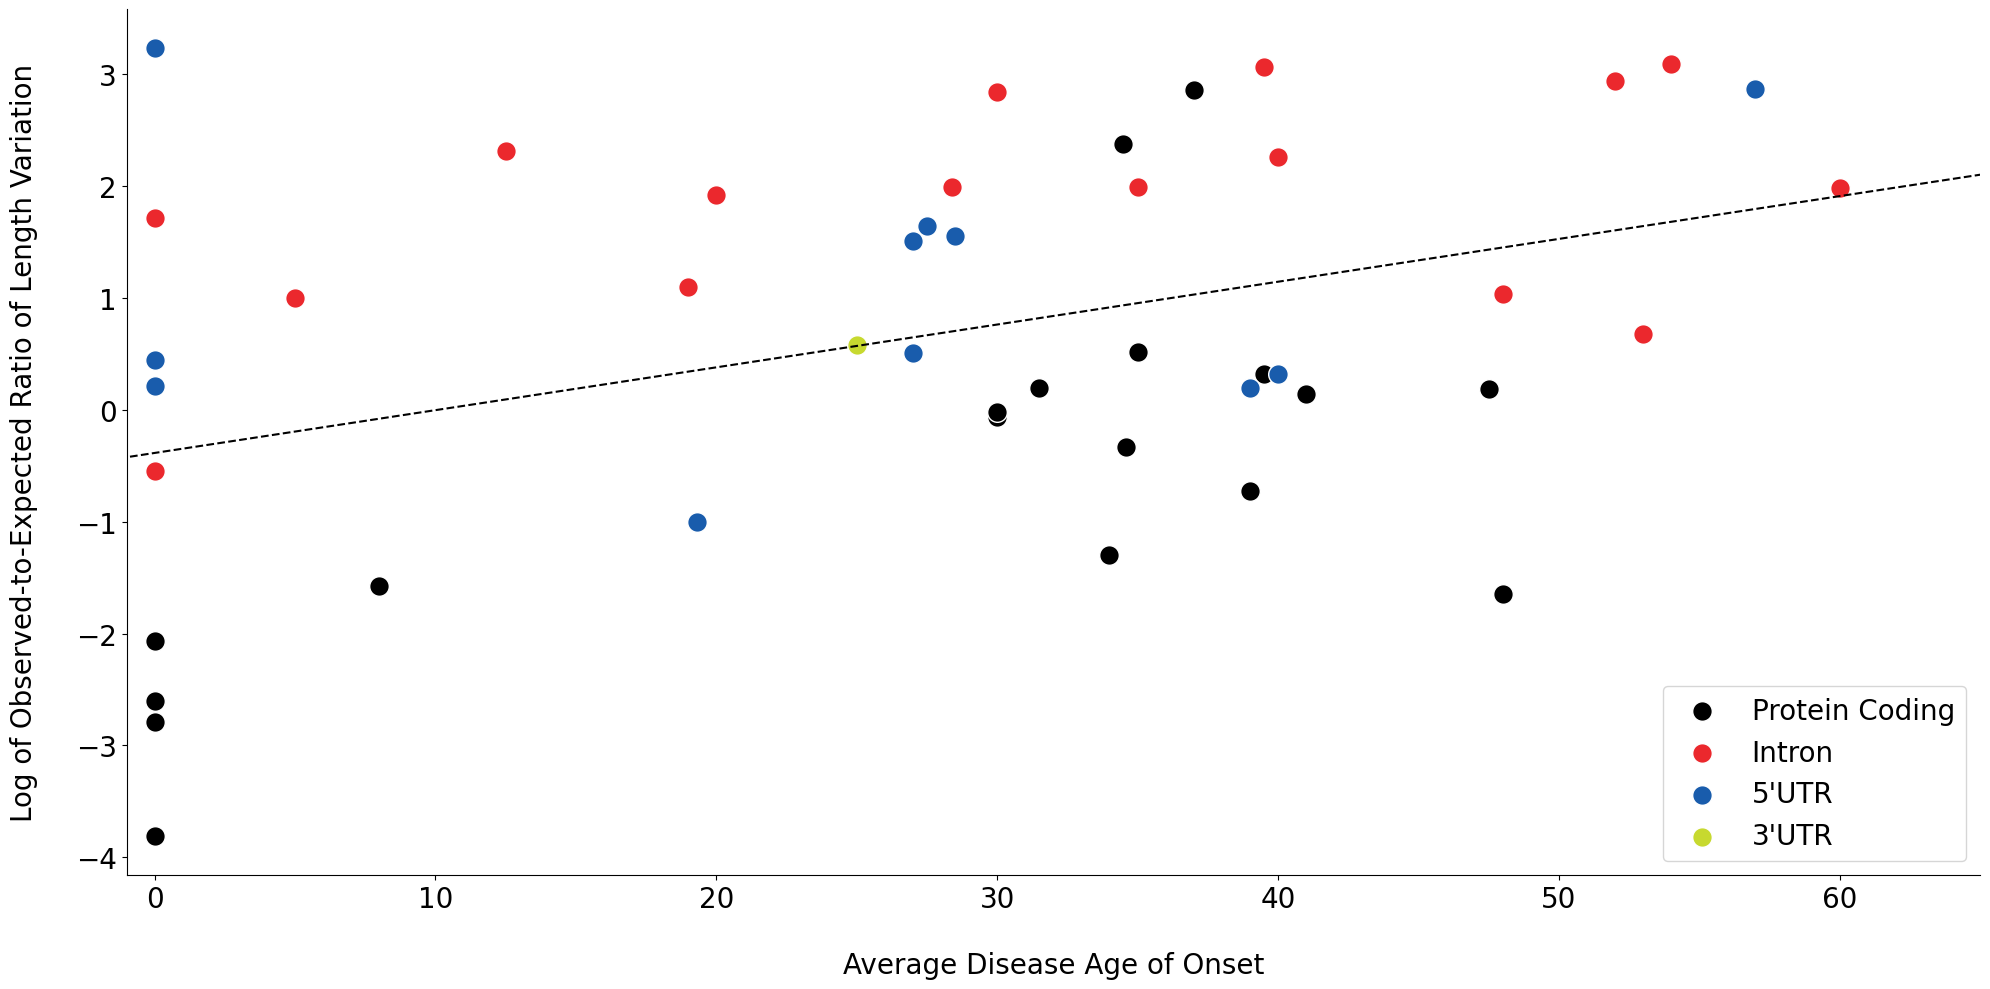

In [ ]:
# plot scatterplot of mean age of onset vs observed/expected ratio, colored by genic region
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(20, 10))
plt.scatter(constraintScores2.loc[constraintScores2['Region']=='coding','mean_age'].values,np.log(constraintScores2.loc[constraintScores2['Region']=='coding','OE_len'].values),c='k',s=200,edgecolor='white',label='Protein Coding')
plt.scatter(constraintScores2.loc[constraintScores2['Region']=='intron','mean_age'].values,np.log(constraintScores2.loc[constraintScores2['Region']=='intron','OE_len'].values),c=colorPalette[2],s=200,edgecolor='white',label='Intron')
plt.scatter(constraintScores2.loc[constraintScores2['Region']=="UTR_5",'mean_age'].values,np.log(constraintScores2.loc[constraintScores2['Region']=="UTR_5",'OE_len'].values),c=colorPalette[5],s=200,edgecolor='white',label="5'UTR")
plt.scatter(constraintScores2.loc[constraintScores2['Region']=="UTR_3",'mean_age'].values,np.log(constraintScores2.loc[constraintScores2['Region']=="UTR_3",'OE_len'].values),c=colorPalette[7],s=200,edgecolor='white',label="3'UTR")

# add best fit line
b,m=polyfit(constraintScores2.loc[:,'mean_age'].values,np.log(constraintScores2.loc[:,'OE_len'].values),1)
x=np.arange(-10,70)
plt.plot(x,b+m*x, '--k')

# finish the plot
plt.xlabel('\nAverage Disease Age of Onset',fontsize=20)
plt.ylabel('Log of Observed-to-Expected Ratio of Length Variation\n',fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.legend(loc='lower right',fontsize=20)
plt.xlim([-1,65])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure23C.png',dpi=600)
plt.savefig('figures/SupplementaryFigure23C.svg')



# S24: TR Length Constraint Performance Benchmark

## S24A

In [1]:
import pandas
import numpy as np
constraintScores=pandas.read_csv('assets/constraintAnalyses/testing_within10kbOfGenes_scoredNT3.bed.gz',sep='\t')
constraintScores['OE_len']=(constraintScores.loc[:,'combinedLPSStdev']+0.1)/(constraintScores.loc[:,'expectedCombinedLPSStdev']+0.1)

pathogenic=pandas.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t',low_memory=False)
sulovariAbInitio=pandas.read_csv('assets/Sulovari_abInitio_TRExplorer_TRIDs.txt',sep='\t',low_memory=False,header=None,names=['TRID'])
sulovariHSE=pandas.read_csv('assets/Sulovari_HSE_TRExplorer_TRIDs.txt',sep='\t',low_memory=False,header=None,names=['TRID'])
codis=pandas.read_csv('assets/CODIS_TRExplorer_TRIDs.txt',sep='\t',low_memory=False,header=None,names=['TRID'])
eSTR=pandas.read_csv('assets/eSTR_TRExplorer_TRIDs_CAVIAR_0.3.txt',sep='\t',low_memory=False,header=None,names=['TRID'])
genicAnnotations=pandas.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',low_memory=False,header=None,names=['TRID','Region'])
coding=genicAnnotations.loc[genicAnnotations['Region']=='coding',:]

# TR length constraint deciles
constraintScores['OEDecile']=0
for idx in range(1,10):
    thresh=constraintScores.loc[:,'OE_len'].quantile(float(f'0.{idx}'))
    constraintScores.loc[constraintScores['OE_len']>thresh,'OEDecile']=idx

# observation deciles
constraintScores['ObsDecile']=0
for idx in range(1,10):
    thresh=constraintScores.loc[:,'combinedLPSStdev'].quantile(float(f'0.{idx}'))
    constraintScores.loc[constraintScores['combinedLPSStdev']>thresh,'ObsDecile']=idx



In [2]:
gymrekConstraint=pandas.read_csv('assets/GymrekConstraint_hg38_with_TRExplorer_TRIDs.txt',sep='\t')
gymrekConstraint=gymrekConstraint.dropna()
gnomadConstraint=pandas.read_csv('assets/gnomad_constraint.txt',sep='\t')
geneNameAssignments=pandas.read_csv('assets/TR_to_gene_name_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','geneName'])
geneNameAssignments=geneNameAssignments.loc[geneNameAssignments['geneName']!='intergenic',:]
gnomadConstraint=gnomadConstraint.merge(geneNameAssignments,how='inner',on='geneName')
# invert gnomad scores so they are analogous to all others
gnomadConstraint['gnomad_oe_lof_inv']=1-gnomadConstraint.loc[:,'gnomad_oe_lof']
gnomadConstraint['gnomad_oe_mis_inv']=1-gnomadConstraint.loc[:,'gnomad_oe_mis']
catalog=pandas.read_csv('assets/variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz',sep='\t',header=None,names=['chrom','start','end','INFO'])
catalog['TRID']=catalog.loc[:,'INFO'].str.split(';',expand=True).iloc[:,0].str.replace('ID=','')
catalog['refSpan']=catalog.loc[:,'end']-catalog.loc[:,'start']+1
refSpan=catalog.loc[:,['TRID','refSpan']]
constraintScores['OE_len_shuf']=np.random.permutation(constraintScores.loc[:,'OE_len'].values)

# gymrekConstraint deciles
gymrekConstraint['GymrekConstraintDecile']=0
for idx in range(1,10):
    thresh=gymrekConstraint.loc[:,'zscore_1'].quantile(float(f'0.{idx}'))
    gymrekConstraint.loc[gymrekConstraint['zscore_1']>thresh,'GymrekConstraintDecile']=idx

# gnomadLoFConstraint deciles
gnomadConstraint['GnomadLoFConstraintDecile']=0
for idx in range(1,10):
    thresh=gnomadConstraint.loc[:,'gnomad_oe_lof_inv'].quantile(float(f'0.{idx}'))
    gnomadConstraint.loc[gnomadConstraint['gnomad_oe_lof_inv']>thresh,'GnomadLoFConstraintDecile']=idx

# gnomadMisConstraint deciles
gnomadConstraint['GnomadMisConstraintDecile']=0
for idx in range(1,10):
    thresh=gnomadConstraint.loc[:,'gnomad_oe_mis_inv'].quantile(float(f'0.{idx}'))
    gnomadConstraint.loc[gnomadConstraint['gnomad_oe_mis_inv']>thresh,'GnomadMisConstraintDecile']=idx

# refSpan deciles
refSpan['refSpanDecile']=0
for idx in range(1,10):
    thresh=refSpan.loc[:,'refSpan'].quantile(float(f'0.{idx}'))
    refSpan.loc[refSpan['refSpan']>thresh,'refSpanDecile']=idx

# shuffled TR-Constraint deciles
constraintScores['shufOEDecile']=0
for idx in range(1,10):
    thresh=constraintScores.loc[:,'OE_len_shuf'].quantile(float(f'0.{idx}'))
    constraintScores.loc[constraintScores['OE_len_shuf']>thresh,'shufOEDecile']=idx


combined=constraintScores.merge(gymrekConstraint,how='outer',on='TRID')
combined=combined.merge(gnomadConstraint,how='outer',on='TRID')
combined=combined.merge(refSpan,how='outer',on='TRID')
combined



,chr,start,end,TRID,mclpsmMedian,mclpsmMAD,mclpsmMean,mclpsmStdev,numUniqueMotifs,lpsMotifVariability,...,geneName,gnomad_oe_mis,gnomad_pLI,gnomad_oe_lof,gnomad_oe_lof_inv,gnomad_oe_mis_inv,GnomadLoFConstraintDecile,GnomadMisConstraintDecile,refSpan,refSpanDecile
0,chr1,100000819.0,100000829.0,1-100000819-100000829-TAG,9.0,0.0,9.000000,0.000000,1.0,0.0,...,SLC35A3,0.68404,0.002604,0.42301,0.57699,0.31596,3.0,7.0,11.0,3.0
1,chr1,100000874.0,100000884.0,1-100000874-100000884-T,10.0,0.0,10.047882,0.222077,1.0,0.0,...,SLC35A3,0.68404,0.002604,0.42301,0.57699,0.31596,3.0,7.0,11.0,3.0
2,chr1,100001444.0,100001454.0,1-100001444-100001454-T,10.0,0.0,10.002762,0.052510,1.0,0.0,...,SLC35A3,0.68404,0.002604,0.42301,0.57699,0.31596,3.0,7.0,11.0,3.0
3,chr1,100002614.0,100002631.0,1-100002614-100002631-TTG,15.0,0.0,15.000000,0.000000,1.0,0.0,...,SLC35A3,0.68404,0.002604,0.42301,0.57699,0.31596,3.0,7.0,18.0,7.0
4,chr1,100002782.0,100002795.0,1-100002782-100002795-T,13.0,0.0,13.181400,0.413220,1.0,0.0,...,SLC35A3,0.68404,0.002604,0.42301,0.57699,0.31596,3.0,7.0,14.0,6.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4442743,NaN,NaN,NaN,Y-9998060-9998076-CAAA,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17.0,7.0
4442744,NaN,NaN,NaN,Y-9998080-9998090-CA,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.0,3.0
4442745,NaN,NaN,NaN,Y-9999271-9999280-TG,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,0.0
4442746,NaN,NaN,NaN,Y-9999279-9999299-T,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.0,8.0


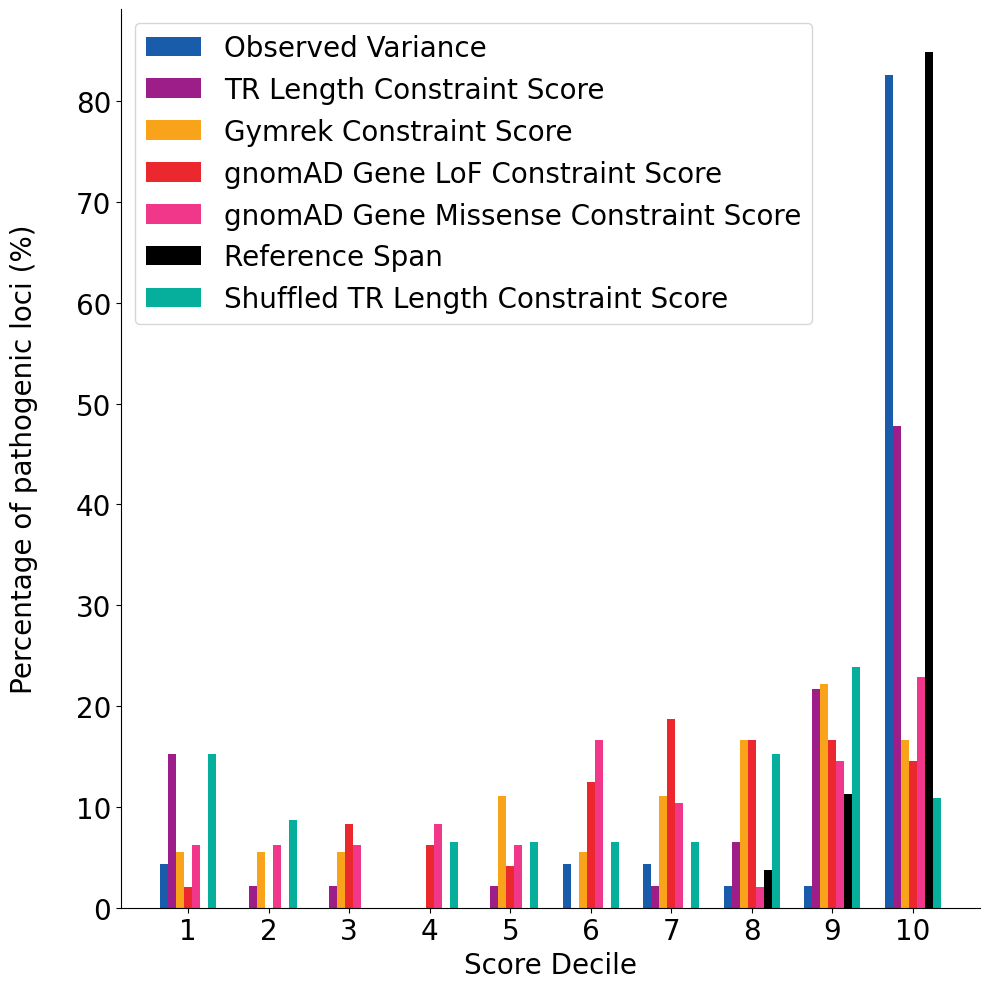

In [ ]:
# plot pathogenic STR enrichment
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
import matplotlib
from matplotlib import pyplot as plt
import numpy as np
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(10, 10))

obsVarianceDeciles=100*combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'ObsDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'ObsDecile'].dropna())
oeDeciles=100*combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'OEDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'OEDecile'].dropna())
gymrekDeciles=100*combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'GymrekConstraintDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'GymrekConstraintDecile'].dropna())
gnomadLofDeciles=100*combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'GnomadLoFConstraintDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'GnomadLoFConstraintDecile'].dropna())
gnomadMisDeciles=100*combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'GnomadMisConstraintDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'GnomadMisConstraintDecile'].dropna())
refSpanDeciles=100*combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'refSpanDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'refSpanDecile'].dropna())
shufDeciles=100*combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'shufOEDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(pathogenic['TRID'].values),'shufOEDecile'].dropna())

# add missing deciles to list
for i in range(10):
    if i not in obsVarianceDeciles.index.values:
        obsVarianceDeciles.loc[i]=0
    if i not in oeDeciles.index.values:
        oeDeciles.loc[i]=0
    if i not in gymrekDeciles.index.values:
        gymrekDeciles.loc[i]=0
    if i not in gnomadLofDeciles.index.values:
        gnomadLofDeciles.loc[i]=0
    if i not in gnomadMisDeciles.index.values:
        gnomadMisDeciles.loc[i]=0
    if i not in refSpanDeciles.index.values:
        refSpanDeciles.loc[i]=0
    if i not in shufDeciles.index.values:
        shufDeciles.loc[i]=0
obsVarianceDeciles=obsVarianceDeciles.sort_index()
oeDeciles=oeDeciles.sort_index()
gymrekDeciles=gymrekDeciles.sort_index()
gnomadLofDeciles=gnomadLofDeciles.sort_index()
gnomadMisDeciles=gnomadMisDeciles.sort_index()
refSpanDeciles=refSpanDeciles.sort_index()
shufDeciles=shufDeciles.sort_index()


width=0.1
x=np.arange(1,11)

plt.bar(x-0.3,obsVarianceDeciles.values,width,label='Observed Variance',color=colorPalette[5])
plt.bar(x-0.3+width,oeDeciles.values,width,label='TR Length Constraint Score',color=colorPalette[4])
plt.bar(x-0.3+width+width,gymrekDeciles.values,width,label='Gymrek Constraint Score',color=colorPalette[1])
plt.bar(x-0.3+width+width+width,gnomadLofDeciles.values,width,label='gnomAD Gene LoF Constraint Score',color=colorPalette[2])
plt.bar(x-0.3+width+width+width+width,gnomadMisDeciles.values,width,label='gnomAD Gene Missense Constraint Score',color=colorPalette[3])
plt.bar(x-0.3+width+width+width+width+width,refSpanDeciles.values,width,label='Reference Span',color='k')
plt.bar(x-0.3+width+width+width+width+width+width,shufDeciles.values,width,label='Shuffled TR Length Constraint Score',color=colorPalette[6])

plt.xticks(x,fontsize=20)
plt.ylabel('Percentage of pathogenic loci (%)\n',fontsize=20)
plt.xlabel('Score Decile',fontsize=20)
plt.yticks(fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.legend(fontsize=20)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure24A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure24A.svg')

## S24B

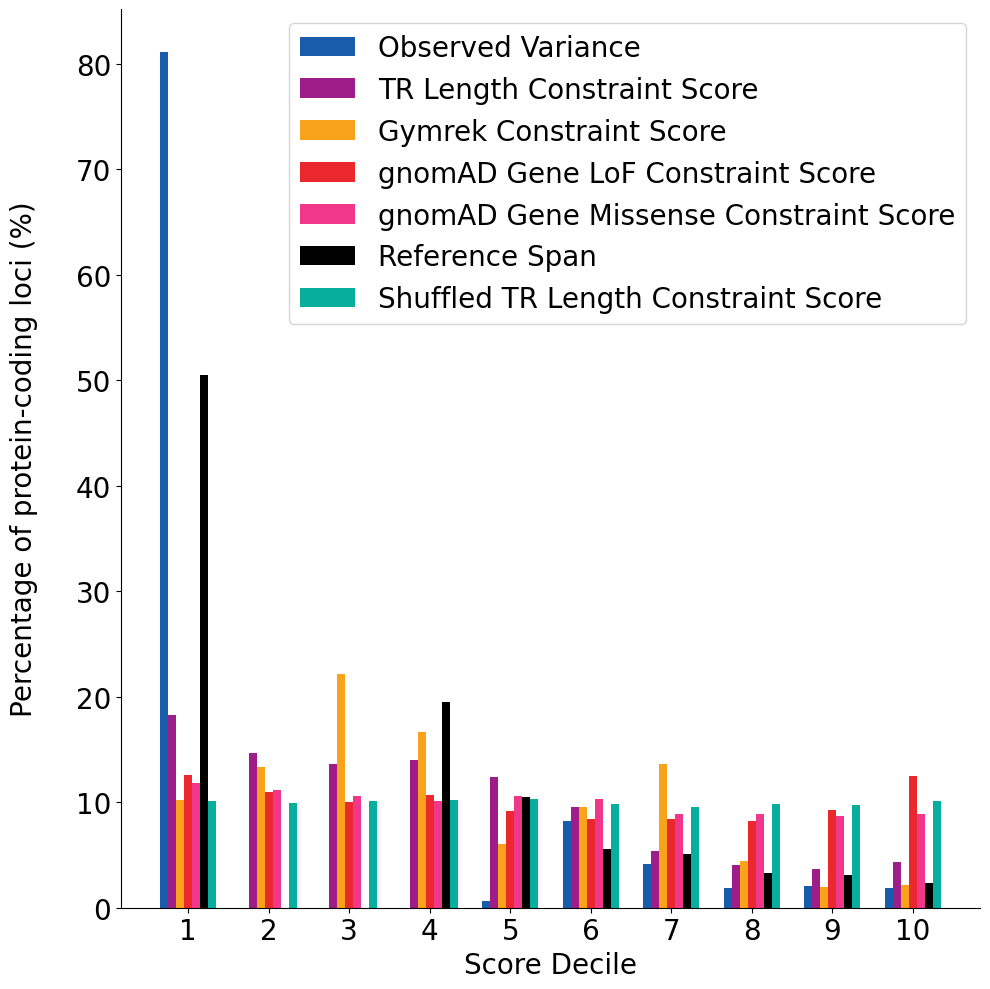

In [ ]:
# plot coding enrichment
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
import matplotlib
from matplotlib import pyplot as plt
import numpy as np
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(10, 10))

obsVarianceDeciles=100*combined.loc[combined['TRID'].isin(coding['TRID'].values),'ObsDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(coding['TRID'].values),'ObsDecile'].dropna())
oeDeciles=100*combined.loc[combined['TRID'].isin(coding['TRID'].values),'OEDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(coding['TRID'].values),'OEDecile'].dropna())
gymrekDeciles=100*combined.loc[combined['TRID'].isin(coding['TRID'].values),'GymrekConstraintDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(coding['TRID'].values),'GymrekConstraintDecile'].dropna())
gnomadLofDeciles=100*combined.loc[combined['TRID'].isin(coding['TRID'].values),'GnomadLoFConstraintDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(coding['TRID'].values),'GnomadLoFConstraintDecile'].dropna())
gnomadMisDeciles=100*combined.loc[combined['TRID'].isin(coding['TRID'].values),'GnomadMisConstraintDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(coding['TRID'].values),'GnomadMisConstraintDecile'].dropna())
refSpanDeciles=100*combined.loc[combined['TRID'].isin(coding['TRID'].values),'refSpanDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(coding['TRID'].values),'refSpanDecile'].dropna())
shufDeciles=100*combined.loc[combined['TRID'].isin(coding['TRID'].values),'shufOEDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(coding['TRID'].values),'shufOEDecile'].dropna())

# add missing deciles to list
for i in range(10):
    if i not in obsVarianceDeciles.index.values:
        obsVarianceDeciles.loc[i]=0
    if i not in oeDeciles.index.values:
        oeDeciles.loc[i]=0
    if i not in gymrekDeciles.index.values:
        gymrekDeciles.loc[i]=0
    if i not in gnomadLofDeciles.index.values:
        gnomadLofDeciles.loc[i]=0
    if i not in gnomadMisDeciles.index.values:
        gnomadMisDeciles.loc[i]=0
    if i not in refSpanDeciles.index.values:
        refSpanDeciles.loc[i]=0
    if i not in shufDeciles.index.values:
        shufDeciles.loc[i]=0
obsVarianceDeciles=obsVarianceDeciles.sort_index()
oeDeciles=oeDeciles.sort_index()
gymrekDeciles=gymrekDeciles.sort_index()
gnomadLofDeciles=gnomadLofDeciles.sort_index()
gnomadMisDeciles=gnomadMisDeciles.sort_index()
refSpanDeciles=refSpanDeciles.sort_index()
shufDeciles=shufDeciles.sort_index()


width=0.1
x=np.arange(1,11)

plt.bar(x-0.3,obsVarianceDeciles.values,width,label='Observed Variance',color=colorPalette[5])
plt.bar(x-0.3+width,oeDeciles.values,width,label='TR Length Constraint Score',color=colorPalette[4])
plt.bar(x-0.3+width+width,gymrekDeciles.values,width,label='Gymrek Constraint Score',color=colorPalette[1])
plt.bar(x-0.3+width+width+width,gnomadLofDeciles.values,width,label='gnomAD Gene LoF Constraint Score',color=colorPalette[2])
plt.bar(x-0.3+width+width+width+width,gnomadMisDeciles.values,width,label='gnomAD Gene Missense Constraint Score',color=colorPalette[3])
plt.bar(x-0.3+width+width+width+width+width,refSpanDeciles.values,width,label='Reference Span',color='k')
plt.bar(x-0.3+width+width+width+width+width+width,shufDeciles.values,width,label='Shuffled TR Length Constraint Score',color=colorPalette[6])

plt.xticks(x,fontsize=20)
plt.ylabel('Percentage of protein-coding loci (%)\n',fontsize=20)
plt.xlabel('Score Decile',fontsize=20)
plt.yticks(fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.legend(fontsize=20)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure24B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure24B.svg')

## S24C

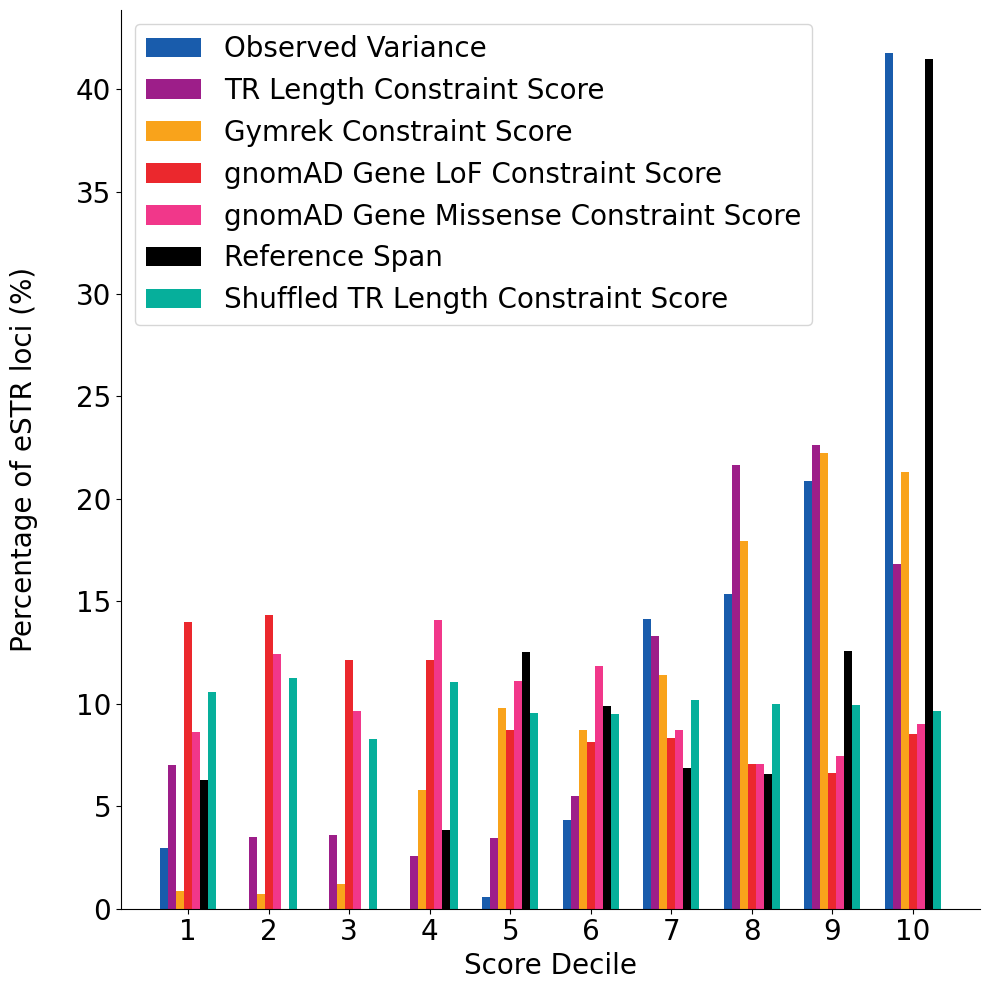

In [ ]:
# plot eSTR enrichment
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
import matplotlib
from matplotlib import pyplot as plt
import numpy as np
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(10, 10))

obsVarianceDeciles=100*combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'ObsDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'ObsDecile'].dropna())
oeDeciles=100*combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'OEDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'OEDecile'].dropna())
gymrekDeciles=100*combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'GymrekConstraintDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'GymrekConstraintDecile'].dropna())
gnomadLofDeciles=100*combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'GnomadLoFConstraintDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'GnomadLoFConstraintDecile'].dropna())
gnomadMisDeciles=100*combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'GnomadMisConstraintDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'GnomadMisConstraintDecile'].dropna())
refSpanDeciles=100*combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'refSpanDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'refSpanDecile'].dropna())
shufDeciles=100*combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'shufOEDecile'].dropna().value_counts().sort_index()/len(combined.loc[combined['TRID'].isin(eSTR['TRID'].values),'shufOEDecile'].dropna())

# add missing deciles to list
for i in range(10):
    if i not in obsVarianceDeciles.index.values:
        obsVarianceDeciles.loc[i]=0
    if i not in oeDeciles.index.values:
        oeDeciles.loc[i]=0
    if i not in gymrekDeciles.index.values:
        gymrekDeciles.loc[i]=0
    if i not in gnomadLofDeciles.index.values:
        gnomadLofDeciles.loc[i]=0
    if i not in gnomadMisDeciles.index.values:
        gnomadMisDeciles.loc[i]=0
    if i not in refSpanDeciles.index.values:
        refSpanDeciles.loc[i]=0
    if i not in shufDeciles.index.values:
        shufDeciles.loc[i]=0
obsVarianceDeciles=obsVarianceDeciles.sort_index()
oeDeciles=oeDeciles.sort_index()
gymrekDeciles=gymrekDeciles.sort_index()
gnomadLofDeciles=gnomadLofDeciles.sort_index()
gnomadMisDeciles=gnomadMisDeciles.sort_index()
refSpanDeciles=refSpanDeciles.sort_index()
shufDeciles=shufDeciles.sort_index()


width=0.1
x=np.arange(1,11)

plt.bar(x-0.3,obsVarianceDeciles.values,width,label='Observed Variance',color=colorPalette[5])
plt.bar(x-0.3+width,oeDeciles.values,width,label='TR Length Constraint Score',color=colorPalette[4])
plt.bar(x-0.3+width+width,gymrekDeciles.values,width,label='Gymrek Constraint Score',color=colorPalette[1])
plt.bar(x-0.3+width+width+width,gnomadLofDeciles.values,width,label='gnomAD Gene LoF Constraint Score',color=colorPalette[2])
plt.bar(x-0.3+width+width+width+width,gnomadMisDeciles.values,width,label='gnomAD Gene Missense Constraint Score',color=colorPalette[3])
plt.bar(x-0.3+width+width+width+width+width,refSpanDeciles.values,width,label='Reference Span',color='k')
plt.bar(x-0.3+width+width+width+width+width+width,shufDeciles.values,width,label='Shuffled TR Length Constraint Score',color=colorPalette[6])

plt.xticks(x,fontsize=20)
plt.ylabel('Percentage of eSTR loci (%)\n',fontsize=20)
plt.xlabel('Score Decile',fontsize=20)
plt.yticks(fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.legend(fontsize=20)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure24C.png',dpi=600)
plt.savefig('figures/SupplementaryFigure24C.svg')

# S25: HAQER Enrichment

## S25A

In [74]:
import pandas
constraintScores=pandas.read_csv('assets/constraintAnalyses/testing_within10kbOfGenes_scoredNT3.bed.gz',sep='\t')
constraintScores['OE_len']=(constraintScores.loc[:,'combinedLPSStdev']+0.1)/(constraintScores.loc[:,'expectedCombinedLPSStdev']+0.1)
constraintScores['OE_alleleLen']=(constraintScores.loc[:,'totalLengthStdev']+0.1)/(constraintScores.loc[:,'expectedTotalLengthStdev']+0.1)

haqer=pandas.read_csv('assets/Eichler_HAQER_TRExplorer_TRIDs.txt',sep='\t',header=None,names=['TRID'])

# genic constraint deciles
constraintScores['OEDecile']=0
for idx in range(1,10):
    thresh=constraintScores.loc[:,'OE_len'].quantile(float(f'0.{idx}'))
    constraintScores.loc[constraintScores['OE_len']>thresh,'OEDecile']=idx

# observation deciles
constraintScores['ObsDecile']=0
for idx in range(1,10):
    thresh=constraintScores.loc[:,'combinedLPSStdev'].quantile(float(f'0.{idx}'))
    constraintScores.loc[constraintScores['combinedLPSStdev']>thresh,'ObsDecile']=idx





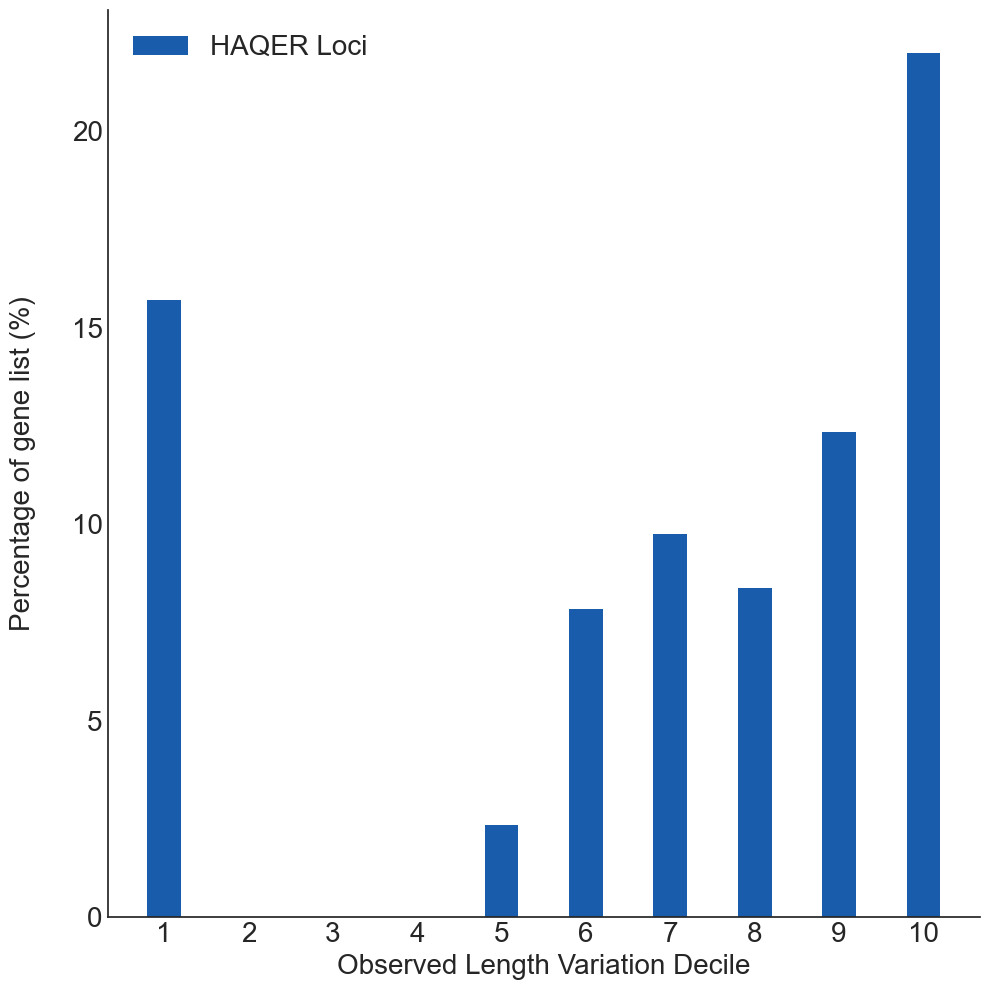

In [ ]:
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
import matplotlib
from matplotlib import pyplot as plt
import numpy as np
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(10, 10))

haqerDeciles=100*constraintScores.loc[constraintScores['TRID'].isin(haqer['TRID'].values),'ObsDecile'].value_counts().sort_index()/len(haqer)

# add missing deciles to list
for i in range(10):
    if i not in haqerDeciles.index.values:
        haqerDeciles.loc[i]=0
haqerDeciles=haqerDeciles.sort_index()


width=0.4
x=np.arange(1,11)

plt.bar(x,haqerDeciles.values,width,label='HAQER Loci',color=colorPalette[5])


plt.xticks(x,fontsize=20)
plt.ylabel('Percentage of gene list (%)\n',fontsize=20)
plt.xlabel('Observed Length Variation Decile',fontsize=20)
plt.yticks(fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.legend(fontsize=20)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure25A.png',dpi=600)
plt.savefig('figures/SupplementaryFigure25A.svg')

## S25B

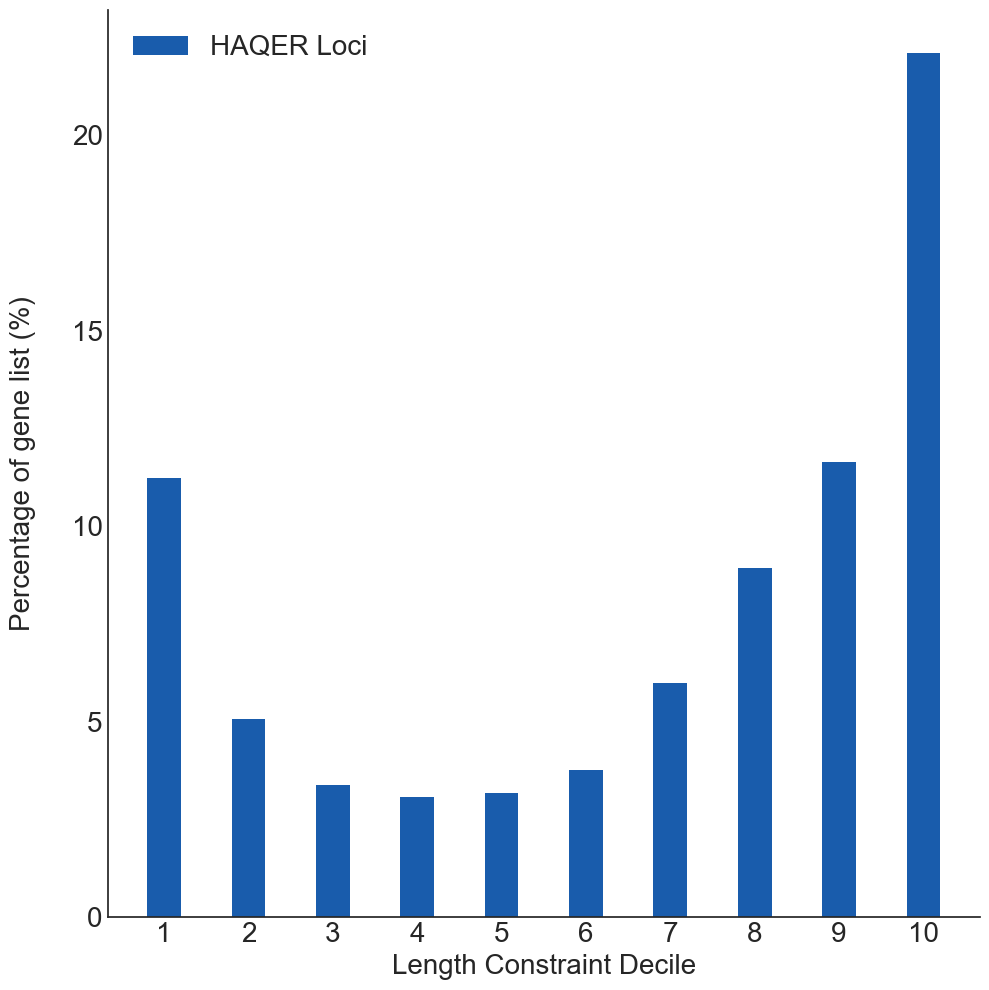

In [ ]:
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']
import matplotlib
from matplotlib import pyplot as plt
import numpy as np
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(10, 10))

haqerDeciles=100*constraintScores.loc[constraintScores['TRID'].isin(haqer['TRID'].values),'OEDecile'].value_counts().sort_index()/len(haqer)

# add missing deciles to list
for i in range(10):
    if i not in haqerDeciles.index.values:
        haqerDeciles.loc[i]=0
haqerDeciles=haqerDeciles.sort_index()


width=0.4
x=np.arange(1,11)

plt.bar(x,haqerDeciles.values,width,label='HAQER Loci',color=colorPalette[5])


plt.xticks(x,fontsize=20)
plt.ylabel('Percentage of gene list (%)\n',fontsize=20)
plt.xlabel('Length Constraint Decile',fontsize=20)
plt.yticks(fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.legend(fontsize=20)
plt.tight_layout()
plt.savefig('figures/SupplementaryFigure25B.png',dpi=600)
plt.savefig('figures/SupplementaryFigure25B.svg')

# Table S3: Candidate CAG and CGG Locus Stats

In [1]:
# initial data loading and package import
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe

from adjustText import adjust_text


# keep SVG text as text (not paths)
mpl.rcParams['svg.fonttype'] = 'none'

# Colors
PALETTE = {"Catalog": "#195CAC", "Pathogenic": "#EB282D"}

lpsPerMotif=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerLocusStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# mark loci where there is no length-level variation, only motif variation
lpsPerMotif['std']=lpsPerMotif['std'].fillna(0)
lpsPerMotif['maxStdev']=lpsPerMotif.groupby('TRID')['std'].transform("max")

# drop to the most common LPS motif per locus
lpsPerMotif=lpsPerMotif.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

annotations=pd.read_csv('assets/genicRegionAnnotations_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','region'])
# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
lpsPerMotif['simpleMotif']=lpsPerMotif.loc[:,'LPS_Motif'].apply(simplest_motif)
lpsPerMotif['motifLen']=lpsPerMotif.loc[:,'simpleMotif'].str.len()

lps=lps.merge(lpsPerMotif.loc[:,['TRID','motifLen','simpleMotif','maxStdev']],how='inner',on='TRID')

# calculate PLVI
lps['PLVI']=lps.groupby('motifLen',observed=True)['std'].rank(pct=True)

# calculate the 95th percentile of stdev for trinucleotides 
lps['motifLen']=lps.loc[:,'simpleMotif'].str.len()
lps=lps.loc[lps['motifLen']==3,:]
ninetyFifth=lps.loc[:,'std'].quantile(0.95)

# drop loci without length-level variation
lps=lps.loc[lps['maxStdev']>0,:]

# keep only the coding CAGs
codingCAG=lps.loc[((lps['simpleMotif']=='AGC') & (lps['TRID'].isin(annotations.loc[annotations['region']=='coding','TRID'].values))),:]

# load pathogenic TRs and TR to geneName conversion tables
pathogenicAnnotated=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
TRToGeneName=pd.read_csv('assets/TR_to_gene_name_TRExplorer.txt.gz',sep='\t',header=None,names=['TRID','geneName'])
pathogenicAnnotated.sort_values(by='geneName',ascending=True)
codingCAG['Status']='Catalog'
codingCAG.loc[codingCAG['TRID'].isin(pathogenicAnnotated['TRID'].values),'Status']='Pathogenic'
codingCAG=codingCAG.merge(TRToGeneName,how='inner',on='TRID')

# Drop Catalog entries for genes that also have a Pathogenic entry (removes same-gene duplicates)
pathogenicCoding=pathogenicAnnotated.loc[pathogenicAnnotated['Region']=='coding','geneName'].values
codingCAG = codingCAG[~((codingCAG['Status'] == 'Catalog') & (codingCAG['geneName'].isin(pathogenicCoding)))].copy()

# get candidate loci (at least PLV of 8 or median LPS length of 35bp)
codingCAGCandidates=codingCAG.loc[(((codingCAG['50thPercentile']>=35) | (codingCAG['std']>=8)) & (codingCAG['Status']=='Catalog') & (codingCAG['geneName']!='AR')),['TRID','geneName','50thPercentile','std','PLVI']]
codingCAGCandidates=codingCAGCandidates.rename(columns={'50thPercentile':'MedianLPSLength','std':'PLV'})
codingCAGCandidates.sort_values(by='PLV',ascending=False)


KeyboardInterrupt: 

In [2]:
len(codingCAGCandidates)

16

In [3]:
# repeat for 5'-UTR CGGs
UTRCGGs=lps.loc[((lps['simpleMotif']=='CCG') & (lps['TRID'].isin(annotations.loc[annotations['region']=='UTR_5','TRID'].values))),:]
UTRCGGs['Status']='Catalog'
UTRCGGs.loc[UTRCGGs['TRID'].isin(pathogenicAnnotated['TRID'].values),'Status']='Pathogenic'
UTRCGGs=UTRCGGs.merge(TRToGeneName,how='inner',on='TRID')

# Drop Catalog entries for genes that also have a Pathogenic entry (removes same-gene duplicates)
pathogenicUTR=pathogenicAnnotated.loc[pathogenicAnnotated['Region']=='UTR_5','geneName'].values
UTRCGGs = UTRCGGs[~((UTRCGGs['Status'] == 'Catalog') & (UTRCGGs['geneName'].isin(pathogenicUTR)))].copy()

UTRCGGCandidates=UTRCGGs.loc[(((UTRCGGs['50thPercentile']>=45) | (UTRCGGs['std']>=8)) & (UTRCGGs['Status']=='Catalog')),['TRID','geneName','50thPercentile','std','PLVI']]
UTRCGGCandidates=UTRCGGCandidates.rename(columns={'50thPercentile':'MedianLPSLength','std':'PLV'})
UTRCGGCandidates.sort_values(by='PLV',ascending=False)


C:\Users\Matt\AppData\Local\Temp\ipykernel_65748\3131995332.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  UTRCGGs['Status']='Catalog'


,TRID,geneName,MedianLPSLength,PLV,PLVI
708,6-149718081-149718093-CGC,LATS1,12.0,26.251980,0.999870
1968,19-12995613-12995630-GCG,NFIX,15.0,22.030846,0.999828
1816,17-7562174-7562184-GCC,SENP3,9.0,20.302676,0.999795
1925,19-17245865-17245875-CGC,NR2F6,9.0,16.265694,0.999686
573,5-177554489-177554531-CGC,FAM193B,36.0,16.101962,0.999679
1233,11-66744819-66744843-GGC,TOP6BL,27.0,14.631937,0.999610
1389,12-50505001-50505022-GGC,DIP2B,21.0,14.353574,0.999594
1783,"17-7885375-7885384-GC,17-7885413-7885430-GGA,1...",CHD3,36.0,14.243635,0.999580
711,6-13328520-13328533-GCC,TBC1D7,12.0,13.656899,0.999538
2189,X-149631735-149631780-CGC,TMEM185A,24.0,11.734748,0.999322


In [4]:
len(UTRCGGCandidates)

35

In [5]:
# merge on TR-Constraint scores and RExPRT ranks
TRConstraint=pd.read_csv('assets/constraintAnalyses/testing_within10kbOfGenes_scoredNT3.bed.gz',sep='\t')
TRConstraint['OE_len']=(TRConstraint.loc[:,'combinedLPSStdev']+0.1)/(TRConstraint.loc[:,'expectedCombinedLPSStdev']+0.1)

rexprt=pd.read_csv('assets/pathoEnrichment/TR_Explorer_v1.0.1.hg19.RExPRTscores.txt.gz',sep='\t')
rexprt=rexprt.rename(columns={'sampleID':'TRID'})
rexprtCodingCAGsSorted=rexprt.loc[rexprt['TRID'].isin(codingCAG.TRID.values),:].sort_values(by='ensembleMax',ascending=True).reset_index(drop=True)
rexprtCodingCAGsSorted['RExPRTClassPercentile']=rexprtCodingCAGsSorted.index/len(rexprtCodingCAGsSorted)
rexprtUTR5CGGsSorted=rexprt.loc[rexprt['TRID'].isin(UTRCGGs.TRID.values),:].sort_values(by='ensembleMax',ascending=True).reset_index(drop=True)
rexprtUTR5CGGsSorted['RExPRTClassPercentile']=rexprtUTR5CGGsSorted.index/len(rexprtUTR5CGGsSorted)

codingCAGCandidates=codingCAGCandidates.merge(TRConstraint.loc[:,['TRID','OE_len']].rename(columns={'OE_len':'TRConstraint'}),how='left',on='TRID')
codingCAGCandidates=codingCAGCandidates.merge(rexprtCodingCAGsSorted.loc[:,['TRID','RExPRTClassPercentile']],how='left',on='TRID')
codingCAGCandidates

,TRID,geneName,MedianLPSLength,PLV,PLVI,TRConstraint,RExPRTClassPercentile
0,1-154869723-154869765-GCT,KCNN3,57.0,6.268946,0.997116,1.055527,0.841706
1,1-153934796-153934847-CTG,DENND4B,27.0,8.496208,0.998510,2.035042,0.728910
2,"2-227598959-227598969-GTG,2-227598971-22759898...",SCYGR2,9.0,13.882924,0.999550,4.916834,0.006635
3,2-217848163-217848190-GCT,TNS1,27.0,10.283769,0.999058,8.224170,0.577251
4,3-40462029-40462059-CTG,RPL14,39.0,6.891482,0.997650,5.094804,0.076777
5,4-139889903-139889966-TGC,MAML3,24.0,13.101689,0.999490,3.208648,0.796209
6,4-139889963-139889982-TGCTGT,MAML3,24.0,13.098520,0.999490,3.943845,0.619905
7,9-2039764-2039824-CAG,SMARCA2,39.0,4.191420,0.993922,0.595710,0.695735
8,11-1584838-1584848-GCA,KRTAP5-1,9.0,10.626097,0.999138,35.417692,0.948815
9,12-6667903-6667945-TGC,ZNF384,39.0,2.059323,0.982994,0.351476,0.681517


In [6]:
UTRCGGCandidates=UTRCGGCandidates.merge(TRConstraint.loc[:,['TRID','OE_len']].rename(columns={'OE_len':'TRConstraint'}),how='left',on='TRID')
UTRCGGCandidates=UTRCGGCandidates.merge(rexprtUTR5CGGsSorted.loc[:,['TRID','RExPRTClassPercentile']],how='left',on='TRID')
UTRCGGCandidates

,TRID,geneName,MedianLPSLength,PLV,PLVI,TRConstraint,RExPRTClassPercentile
0,2-168247544-168247562-CCG,STK39,30.0,8.748341,0.998602,12.949111,0.901978
1,2-111120967-111121021-GCC,BCL2L11,33.0,9.309413,0.998789,1.453721,0.663669
2,3-63863951-63863978-CGC,ATXN7,27.0,9.611590,0.998877,3.105481,0.248651
3,5-443220-443277-GGC,EXOC3,27.0,11.356158,0.999268,1.550920,0.495054
4,5-177554489-177554531-CGC,FAM193B,36.0,16.101962,0.999679,2.461434,0.747302
5,6-34792126-34792141-GGC,BLTP3A,15.0,9.009952,0.998700,10.861940,0.424011
6,6-149718081-149718093-CGC,LATS1,12.0,26.251980,0.999870,75.853684,0.497752
7,6-13328520-13328533-GCC,TBC1D7,12.0,13.656899,0.999538,27.611952,0.340827
8,7-100694312-100694381-CCG,GIGYF1,36.0,10.930737,0.999195,1.267477,0.004047
9,10-50991310-50991343-GCC,PRKG1,33.0,11.573691,0.999295,2.186401,0.707734


In [7]:
catalog=pd.read_csv('assets/variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz',sep='\t',header=None,names=['chrom','start','end','INFO'])
catalog['TRID']=catalog.loc[:,'INFO'].str.split(';',expand=True).iloc[:,0].str[3:]
catalog['genomicLocation']=catalog.loc[:,'chrom'].astype(str) + ':' + catalog.loc[:,'start'].astype(str) + '-' + catalog.loc[:,'end'].astype(str)
catalog=catalog.loc[:,['TRID','genomicLocation']]
catalog

,TRID,genomicLocation
0,1-49834-49853-AAAC,chr1:49834-49853
1,1-49846-49861-AAACA,chr1:49846-49861
2,1-50139-50148-TAA,chr1:50139-50148
3,1-50481-50513-GT,chr1:50481-50513
4,1-50519-50529-GA,chr1:50519-50529
...,...,...
4439808,Y-56886703-56886715-AATG,chrY:56886703-56886715
4439809,Y-56886790-56886799-T,chrY:56886790-56886799
4439810,Y-56886965-56886980-TTTC,chrY:56886943-56886980
4439811,Y-56887111-56887141-GTT,chrY:56887101-56887165


In [8]:
codingCAGCandidates['Class']='CodingCAG'
UTRCGGCandidates['Class']='UTR5CGG'
tableS5=pd.concat([codingCAGCandidates,UTRCGGCandidates],ignore_index=True)

# get the coordinates of each locus
catalog=pd.read_csv('assets/variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz',sep='\t',header=None,names=['chrom','start','end','INFO'])
catalog['TRID']=catalog.loc[:,'INFO'].str.split(';',expand=True).iloc[:,0].str[3:]
catalog['genomicLocation']=catalog.loc[:,'chrom'].astype(str) + ':' + catalog.loc[:,'start'].astype(str) + '-' + catalog.loc[:,'end'].astype(str)
catalog=catalog.loc[:,['TRID','genomicLocation']]
tableS5=tableS5.merge(catalog,how='inner',on='TRID')

tableS5=tableS5.loc[:,['TRID','genomicLocation','geneName','Class','MedianLPSLength','PLV','PLVI','TRConstraint','RExPRTClassPercentile']]
tableS5.to_csv('assets/candidateLoci_stats.txt',sep='\t',index=False)
tableS5

,TRID,genomicLocation,geneName,Class,MedianLPSLength,PLV,PLVI,TRConstraint,RExPRTClassPercentile
0,1-154869723-154869765-GCT,chr1:154869723-154869765,KCNN3,CodingCAG,57.0,6.268946,0.997116,1.055527,0.841706
1,1-153934796-153934847-CTG,chr1:153934796-153934847,DENND4B,CodingCAG,27.0,8.496208,0.998510,2.035042,0.728910
2,"2-227598959-227598969-GTG,2-227598971-22759898...",chr2:227598937-227599100,SCYGR2,CodingCAG,9.0,13.882924,0.999550,4.916834,0.006635
3,2-217848163-217848190-GCT,chr2:217848163-217848190,TNS1,CodingCAG,27.0,10.283769,0.999058,8.224170,0.577251
4,3-40462029-40462059-CTG,chr3:40462029-40462059,RPL14,CodingCAG,39.0,6.891482,0.997650,5.094804,0.076777
5,4-139889903-139889966-TGC,chr4:139889903-139889966,MAML3,CodingCAG,24.0,13.101689,0.999490,3.208648,0.796209
6,4-139889963-139889982-TGCTGT,chr4:139889909-139889982,MAML3,CodingCAG,24.0,13.098520,0.999490,3.943845,0.619905
7,9-2039764-2039824-CAG,chr9:2039764-2039824,SMARCA2,CodingCAG,39.0,4.191420,0.993922,0.595710,0.695735
8,11-1584838-1584848-GCA,chr11:1584674-1584920,KRTAP5-1,CodingCAG,9.0,10.626097,0.999138,35.417692,0.948815
9,12-6667903-6667945-TGC,chr12:6667903-6667945,ZNF384,CodingCAG,39.0,2.059323,0.982994,0.351476,0.681517


In [9]:
tableS5.loc[tableS5['TRID'].str.startswith('2-227598959-227598969-GTG,'),'TRID'].values

array(['2-227598959-227598969-GTG,2-227598971-227598981-GTG,2-227598995-227599005-GTG,2-227599007-227599017-GTG,2-227599091-227599100-GCT'],
      dtype=object)